# Part 1 of 3: Cohorts, prediction tasks, event logs and the leakage risk surface

**Study:** Data leakage in ICU prediction pipelines built on MIMIC-IV and eICU-CRD

**Purpose of this notebook**

1. Build harmonised adult ICU cohorts in MIMIC-IV (single centre) and eICU-CRD (multi-centre) with a fixed prediction time of 24 hours after ICU admission, and record every exclusion.
2. Define three prediction tasks that dominate the ICU prediction literature: in-hospital mortality, prolonged ICU stay (more than 4 days) and acute kidney injury (KDIGO creatinine criteria) between 24 and 72 hours.
3. Extract time-stamped event logs in which every value carries two clocks: the **clinical time** (when it was measured) and the **availability time** (when it was stored, entered or resulted). Interval events (infusions, ventilation) also carry their end time.
4. Extract the stay-level fields that are only known in hindsight or that act as outcome proxies (discharge fields, length of stay, billing codes, APACHE outcome columns, care limitation and code status). Part 2 uses them to build leaky pipelines on purpose.
5. Assign leakage-safe splits: patient-grouped, temporal (true calendar period) and, for eICU-CRD, hospital-held-out.
6. Quantify the **leakage risk surface** of both databases: how often patients recur, how long results take to become available, how much of the record is written after the prediction time, how often outcome proxies are documented, and when outcomes occur relative to the prediction time.
7. Build the leakage-safe baseline feature set and certify it with `icu-leakage-check` before any modelling.

**Outputs** (all under `WORK_DIR/part1/`)

| Folder | Contents | Sharing |
|---|---|---|
| `data/` | cohorts, event logs, hindsight fields, baseline features (one row per stay or event) | Private. Never upload or commit. |
| `private_reports/` | full audit reports (may list identifiers) | Private |
| `results/tables`, `results/figures` | aggregate tables and figures, counts below 10 suppressed | Shareable |
| `manifest_part1.json` | SHA-256 hash of every output, configuration and software versions, chained into one digest | Shareable |

**Before running**

* Select the kernel **Python (icu-leakage-check)**.
* Install the plotting library once in that environment: `pip install matplotlib`.
* For a quick test set `MAX_STAYS = 5000` in the configuration cell, then set it back to `None` for the full run.

## 1. Configuration

Paths point to the Parquet folders created with `icu-leakage-check convert`. The original CSV folders also work, more slowly.
All times in this study are **minutes from ICU admission**, in both databases. eICU-CRD stores time this way natively; MIMIC-IV
timestamps are converted. This avoids comparing MIMIC-IV dates across patients, which are shifted per patient.

In [3]:
import os
from pathlib import Path

ROOTS = {
    "mimic-iv": Path(os.environ.get("ILC_MIMIC_ROOT", r"C:\icu_parquet\mimic")),
    "eicu": Path(os.environ.get("ILC_EICU_ROOT", r"C:\icu_parquet\eicu")),
}
WORK_DIR = Path(os.environ.get("ILC_WORK_DIR", r"C:\icu_leakage_work"))

MAX_STAYS = None   # set to 5000 for a quick test run, then back to None for the full cohort
if os.environ.get("ILC_MAX_STAYS"):
    MAX_STAYS = int(os.environ["ILC_MAX_STAYS"])
SEED = 20261015

INDEX_MIN = 24 * 60            # prediction time: 24 h after ICU admission
EARLY_INDEX_MIN = 6 * 60       # secondary prediction time used in Part 2
LOOKAHEAD_MIN = 48 * 60        # events extracted after admission (beyond the prediction time for leaky variants)
OTHER_LOOKBACK_MIN = 24 * 60   # laboratory history before ICU admission
CREAT_LOOKBACK_MIN = 7 * 24 * 60   # creatinine history for the KDIGO baseline
AKI_HORIZON_MIN = 72 * 60      # AKI outcome window ends 72 h after admission
LONG_STAY_MIN = 96 * 60        # prolonged ICU stay: more than 4 days

PATIENT_TEST, PATIENT_VALID = 0.20, 0.10
SITE_TEST_FRACTION = 0.20
MIN_CELL = 10                  # counts below this are suppressed in shareable tables
DUCKDB_MEMORY = "3GB"
DUCKDB_THREADS = None          # None lets DuckDB decide

In [4]:
import hashlib
import json
import platform
import sys
import time
import warnings
from datetime import datetime, timezone

import duckdb
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn

import icu_leakage_check as ilc

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 80)
pd.set_option("display.max_colwidth", 60)

RUN_START = time.time()
PART_DIR = WORK_DIR / "part1"
DATA_DIR = PART_DIR / "data"
RESULTS_DIR = PART_DIR / "results"
TABLES_DIR = RESULTS_DIR / "tables"
FIG_DIR = RESULTS_DIR / "figures"
PRIVATE_DIR = PART_DIR / "private_reports"
TMP_DIR = WORK_DIR / "duckdb_tmp"
for d in (DATA_DIR, TABLES_DIR, FIG_DIR, PRIVATE_DIR, TMP_DIR):
    d.mkdir(parents=True, exist_ok=True)

ENV = {
    "run_started_utc": datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ"),
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "processor": platform.processor(),
    "icu_leakage_check": ilc.__version__,
    "pandas": pd.__version__,
    "numpy": np.__version__,
    "scikit_learn": sklearn.__version__,
    "duckdb": duckdb.__version__,
    "matplotlib": matplotlib.__version__,
}
CONFIG = {k: (str(v) if isinstance(v, Path) else v) for k, v in {
    "ROOTS": {k: str(v) for k, v in ROOTS.items()}, "MAX_STAYS": MAX_STAYS, "SEED": SEED,
    "INDEX_MIN": INDEX_MIN, "EARLY_INDEX_MIN": EARLY_INDEX_MIN, "LOOKAHEAD_MIN": LOOKAHEAD_MIN,
    "OTHER_LOOKBACK_MIN": OTHER_LOOKBACK_MIN, "CREAT_LOOKBACK_MIN": CREAT_LOOKBACK_MIN,
    "AKI_HORIZON_MIN": AKI_HORIZON_MIN, "LONG_STAY_MIN": LONG_STAY_MIN, "PATIENT_TEST": PATIENT_TEST,
    "PATIENT_VALID": PATIENT_VALID, "SITE_TEST_FRACTION": SITE_TEST_FRACTION, "MIN_CELL": MIN_CELL,
}.items()}
print(json.dumps(ENV, indent=2))

{
  "run_started_utc": "2026-10-16T00:23:44Z",
  "python": "3.11.5",
  "platform": "Windows-10-10.0.26200-SP0",
  "processor": "Intel64 Family 6 Model 181 Stepping 0, GenuineIntel",
  "icu_leakage_check": "0.1.0",
  "pandas": "3.0.6",
  "numpy": "2.4.6",
  "scikit_learn": "1.9.1",
  "duckdb": "1.5.6",
  "matplotlib": "3.11.2"
}


### 1.1 Check that every required table is present

In [5]:
REQUIRED = {
    "mimic-iv": ["patients", "admissions", "icustays", "chartevents", "labevents", "outputevents", "inputevents",
                 "procedureevents", "diagnoses_icd", "drgcodes", "d_items", "d_labitems"],
    "eicu": ["patient", "hospital", "lab", "vitalPeriodic", "vitalAperiodic", "nurseCharting", "intakeOutput",
             "infusionDrug", "treatment", "apacheApsVar", "apachePredVar", "apachePatientResult", "diagnosis",
             "carePlanGeneral", "carePlanEOL"],
}
for db, tables in REQUIRED.items():
    listing = ilc.list_tables(ROOTS[db], db).set_index("table")
    sub = listing.loc[tables, ["found", "size_mb", "path"]]
    print(f"\n{db}: {int(sub['found'].sum())} of {len(tables)} required tables found under {ROOTS[db]}")
    display(sub)
    missing = sub.index[~sub["found"]].tolist()
    if missing:
        raise FileNotFoundError(
            f"{db} is missing {missing}. Convert them with: icu-leakage-check convert --dataset {db} "
            f"--root <original csv folder> --out \"{ROOTS[db]}\" --tables {','.join(missing)}"
        )


mimic-iv: 12 of 12 required tables found under C:\icu_parquet\mimic


,found,size_mb,path
table,,,
patients,True,1.2,C:\icu_parquet\mimic\hosp\patients.parquet
admissions,True,13.1,C:\icu_parquet\mimic\hosp\admissions.parquet
icustays,True,2.0,C:\icu_parquet\mimic\icu\icustays.parquet
chartevents,True,1231.6,C:\icu_parquet\mimic\icu\chartevents.parquet
labevents,True,1091.3,C:\icu_parquet\mimic\hosp\labevents.parquet
outputevents,True,38.9,C:\icu_parquet\mimic\icu\outputevents.parquet
inputevents,True,236.8,C:\icu_parquet\mimic\icu\inputevents.parquet
procedureevents,True,20.6,C:\icu_parquet\mimic\icu\procedureevents.parquet
diagnoses_icd,True,15.9,C:\icu_parquet\mimic\hosp\diagnoses_icd.parquet



eicu: 15 of 15 required tables found under C:\icu_parquet\eicu


,found,size_mb,path
table,,,
patient,True,6.1,C:\icu_parquet\eicu\patient.parquet
hospital,True,0.0,C:\icu_parquet\eicu\hospital.parquet
lab,True,447.0,C:\icu_parquet\eicu\lab.parquet
vitalPeriodic,True,1389.0,C:\icu_parquet\eicu\vitalPeriodic.parquet
vitalAperiodic,True,167.9,C:\icu_parquet\eicu\vitalAperiodic.parquet
nurseCharting,True,1569.4,C:\icu_parquet\eicu\nurseCharting.parquet
intakeOutput,True,190.0,C:\icu_parquet\eicu\intakeOutput.parquet
infusionDrug,True,42.5,C:\icu_parquet\eicu\infusionDrug.parquet
treatment,True,25.2,C:\icu_parquet\eicu\treatment.parquet


### 1.2 Helpers

DuckDB reads only the columns and rows each query needs, so the largest tables (MIMIC-IV `chartevents`, eICU-CRD
`vitalPeriodic` and `nurseCharting`) never have to fit in memory. Event logs are stored in a compact canonical format
(`entity_id, variable, value, event_time, available_time, end_time, source`), the same format used by `icu-leakage-check`.

In [6]:
con = duckdb.connect()
con.execute(f"SET memory_limit='{DUCKDB_MEMORY}'")
con.execute(f"SET temp_directory='{TMP_DIR.as_posix()}'")
con.execute("SET preserve_insertion_order=false")
if DUCKDB_THREADS:
    con.execute(f"SET threads={int(DUCKDB_THREADS)}")


def src(db, table):
    path = ilc.find_table(ROOTS[db], table, db)
    p = path.as_posix().replace("'", "''")
    if path.name.lower().endswith(".parquet"):
        return f"read_parquet('{p}')"
    return f"read_csv_auto('{p}', sample_size=-1)"


def q(sql, **frames):
    # Run SQL and return a DataFrame; keyword arguments are registered as tables
    for name, frame in frames.items():
        con.register(name, frame)
    try:
        return con.execute(sql).df()
    finally:
        for name in frames:
            con.unregister(name)


def run(sql, **frames):
    for name, frame in frames.items():
        con.register(name, frame)
    try:
        con.execute(sql)
    finally:
        for name in frames:
            con.unregister(name)


class Flow:
    # Records the number of stays and patients after every cohort step
    def __init__(self, db):
        self.db, self.rows = db, []

    def step(self, label, df, stay_col, patient_col):
        self.rows.append({"database": self.db, "step": label, "stays": int(df[stay_col].nunique()),
                          "patients": int(df[patient_col].nunique())})
        print(f"{self.db:9s} {label:60s} stays={self.rows[-1]['stays']:>8,}  patients={self.rows[-1]['patients']:>8,}")

    def frame(self):
        f = pd.DataFrame(self.rows)
        f["excluded_stays"] = (f["stays"].shift(1) - f["stays"]).fillna(0).astype(int)
        return f


EVENT_COLS = ["entity_id", "variable", "value", "event_time", "available_time", "end_time", "source"]


def compact(ev, source):
    ev = ev.copy()
    if "end_time" not in ev:
        ev["end_time"] = np.nan
    if "available_time" not in ev:
        ev["available_time"] = ev["event_time"]
    ev["source"] = source
    ev = ev[EVENT_COLS]
    ev["entity_id"] = ev["entity_id"].astype("int64")
    for c in ("value", "event_time", "available_time", "end_time"):
        ev[c] = pd.to_numeric(ev[c], errors="coerce").astype("float32")
    ev["available_time"] = np.maximum(ev["available_time"].fillna(ev["event_time"]), ev["event_time"]).astype("float32")
    ev["variable"] = ev["variable"].astype(str).astype("category")
    ev["source"] = ev["source"].astype("category")
    return ev.dropna(subset=["value", "event_time"]).reset_index(drop=True)


def minutes_between(later, earlier):
    return (later - earlier).dt.total_seconds() / 60.0


def sample_by_patient(df, patient_col, max_stays, seed):
    # Keep whole patients (all their stays) so repeat-stay structure is preserved
    if not max_stays or len(df) <= max_stays:
        return df
    pats = df[patient_col].drop_duplicates().sample(frac=1.0, random_state=seed)
    counts = df.groupby(patient_col).size().reindex(pats).cumsum()
    keep = set(counts[counts <= max_stays].index)
    return df[df[patient_col].isin(keep)].copy()


def suppress(df, count_cols, min_cell=MIN_CELL):
    out = df.copy()
    for c in count_cols:
        if c in out:
            out[c] = out[c].map(lambda v: f"<{min_cell}" if pd.notna(v) and 0 < v < min_cell else v)
    return out


SORT_KEYS = ["database", "stay_id", "entity_id", "variable", "event_time", "chart_min", "available_time", "end_time", "value"]


def save_parquet(df, name):
    # Rows are sorted before saving so repeated runs produce byte-identical files and identical hashes
    path = DATA_DIR / f"{name}.parquet"
    keys = [k for k in SORT_KEYS if k in df.columns]
    if keys:
        df = df.sort_values(keys, kind="mergesort").reset_index(drop=True)
    df.to_parquet(path, index=False)
    return path


def save_table(df, name):
    path = TABLES_DIR / f"{name}.csv"
    df.to_csv(path, index=False, float_format="%.6g")
    return path


def save_fig(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=300, bbox_inches="tight", metadata={"Software": None})
    fig.savefig(FIG_DIR / f"{name}.pdf", bbox_inches="tight", metadata={"CreationDate": None, "Producer": None, "Creator": None})


def lag_stats(raw, db, source):
    # Availability lag (minutes) for values charted in the first 24 h, and late arrivals after the prediction time
    r = raw[(raw["chart_min"] > 0) & (raw["chart_min"] <= INDEX_MIN) & raw["store_min"].notna()]
    if r.empty:
        return pd.DataFrame()
    lag = r["store_min"] - r["chart_min"]
    g = r.assign(lag=lag, late=(r["store_min"] > INDEX_MIN).astype(int)).groupby("variable", observed=True)
    out = g.agg(n_events=("lag", "size"), median_lag_min=("lag", "median"),
                p90_lag_min=("lag", lambda s: s.quantile(0.9)), share_lag_over_60_min=("lag", lambda s: (s > 60).mean()),
                late_arrivals=("late", "sum")).reset_index()
    out["late_arrival_share"] = out["late_arrivals"] / out["n_events"]
    out.insert(0, "source", source)
    out.insert(0, "database", db)
    return out


def kdigo_creatinine(cr, index_min, horizon_min):
    # KDIGO creatinine criteria: rise >= 0.3 mg/dL within 48 h, or >= 1.5 x the lowest value in the previous 7 days
    rows = []
    for sid, g in cr.groupby("entity_id", sort=False):
        t = g["event_time"].to_numpy(float)
        v = g["value"].to_numpy(float)
        o = np.argsort(t, kind="mergesort")
        t, v = t[o], v[o]
        hit = np.zeros(len(t), dtype=bool)
        for k in range(len(t)):
            prev7 = (t < t[k]) & (t >= t[k] - 7 * 1440)
            prev48 = (t < t[k]) & (t >= t[k] - 2 * 1440)
            if (prev7.any() and v[k] >= 1.5 * v[prev7].min()) or (prev48.any() and v[k] - v[prev48].min() >= 0.3):
                hit[k] = True
        base = t <= index_min
        future = (t > index_min) & (t <= horizon_min) & hit
        rows.append((sid, v[base].min() if base.any() else np.nan, bool(hit[base].any()), bool(future.any()),
                     t[future].min() if future.any() else np.nan, bool(((t > index_min) & (t <= horizon_min)).any())))
    return pd.DataFrame(rows, columns=["stay_id", "aki_baseline_creatinine", "aki_at_or_before_index", "aki",
                                       "aki_time", "creatinine_measured_in_window"])


ALL_VARIABLES = ["heart_rate", "resp_rate", "spo2", "temperature", "map_invasive", "map_nibp", "sbp_nibp", "gcs_total",
                 "gcs_eye", "gcs_verbal", "gcs_motor", "lactate", "creatinine", "bun", "wbc", "platelets", "potassium",
                 "sodium", "bicarbonate", "bilirubin", "hemoglobin", "glucose", "ph", "urine_output", "norepinephrine",
                 "epinephrine", "vasopressin", "phenylephrine", "dopamine", "dobutamine", "invasive_ventilation",
                 "noninvasive_ventilation", "mech_vent_documented"]
VARCODES = pd.DataFrame({"variable": ALL_VARIABLES, "code": np.arange(len(ALL_VARIABLES), dtype="int16")})


def decode(df, col="var_code"):
    # Large query results carry a small integer code instead of millions of strings; decode to a categorical
    df["variable"] = pd.Categorical.from_codes(df.pop(col).astype("int16"), categories=ALL_VARIABLES)
    return df


def lag_stats_sql(table, db, source):
    # Same statistics as lag_stats, computed inside DuckDB for very large tables
    out = q(f'''
    SELECT variable, count(*) AS n_events, median(store_min - chart_min) AS median_lag_min,
           quantile_cont(store_min - chart_min, 0.9) AS p90_lag_min,
           avg(CASE WHEN store_min - chart_min > 60 THEN 1.0 ELSE 0.0 END) AS share_lag_over_60_min,
           sum(CASE WHEN store_min > {INDEX_MIN} THEN 1 ELSE 0 END) AS late_arrivals
    FROM {table} WHERE chart_min > 0 AND chart_min <= {INDEX_MIN} AND store_min IS NOT NULL
    GROUP BY variable''')
    out["late_arrival_share"] = out["late_arrivals"] / out["n_events"]
    out = out.sort_values("variable").reset_index(drop=True)
    out.insert(0, "source", source)
    out.insert(0, "database", db)
    return out


OKABE = {"mimic-iv": "#0072B2", "eicu": "#E69F00"}
LABEL = {"mimic-iv": "MIMIC-IV", "eicu": "eICU-CRD"}
LAG_TABLES, MISSING_TABLES, FLOWS, HAZARD_SOURCES = [], [], {}, {}
print("helpers ready")

helpers ready


## 2. MIMIC-IV

### 2.1 Cohort

All ICU stays (`icu.icustays`) of adults, still in the ICU at the prediction time and alive at the prediction time. Every
stay is kept, including repeat stays of the same patient, so that Part 2 can quantify patient overlap between splits;
`stay_number` and `is_first_stay` allow first-stay analyses. Age is `anchor_age + year(intime) - anchor_year`. In-hospital
death uses `hospital_expire_flag`; the death time is `deathtime`, or `dischtime` when `deathtime` is missing.

Both eligibility criteria (in the ICU and alive at 24 hours) are known at the prediction time, so they do not use future
information. A model scored at 6 hours on this same cohort would, which Part 2 uses as one of its experiments.

In [7]:
DB = "mimic-iv"
R = ROOTS[DB]
flow = Flow(DB)

icu = ilc.read_table(R, "icustays", DB)
adm = ilc.read_table(R, "admissions", DB, columns=["subject_id", "hadm_id", "admittime", "dischtime", "deathtime",
                                                   "hospital_expire_flag", "discharge_location"])
pat = ilc.read_table(R, "patients", DB, columns=["subject_id", "gender", "anchor_age", "anchor_year", "anchor_year_group"])
m = icu.merge(adm, on=["subject_id", "hadm_id"], how="left").merge(pat, on="subject_id", how="left")
flow.step("All ICU stays", m, "stay_id", "subject_id")

m["age"] = m["anchor_age"] + (m["intime"].dt.year - m["anchor_year"])
m = m[m["age"] >= 18].copy()
flow.step("Aged 18 years or older", m, "stay_id", "subject_id")

m = m[m["intime"].notna() & m["outtime"].notna()].copy()
m["icu_minutes"] = minutes_between(m["outtime"], m["intime"])
m = m[m["icu_minutes"] >= INDEX_MIN].copy()
flow.step("Still in the ICU 24 h after admission", m, "stay_id", "subject_id")

died = m["hospital_expire_flag"].fillna(0).astype(int) == 1
death_time = m["deathtime"].where(m["deathtime"].notna(), m["dischtime"])
m["mortality"] = died.astype(int)
m["mortality_time"] = np.where(died, minutes_between(death_time, m["intime"]), np.nan)
m = m[~((m["mortality"] == 1) & (m["mortality_time"] <= INDEX_MIN))].copy()
flow.step("Alive 24 h after ICU admission", m, "stay_id", "subject_id")

if MAX_STAYS:
    m = sample_by_patient(m, "subject_id", MAX_STAYS, SEED)
    flow.step(f"Quick-run sample of whole patients (MAX_STAYS={MAX_STAYS})", m, "stay_id", "subject_id")

m = m.sort_values(["subject_id", "intime"]).reset_index(drop=True)
m["stay_number"] = m.groupby("subject_id").cumcount() + 1
m["n_stays_patient"] = m.groupby("subject_id")["stay_id"].transform("size")
m["long_stay"] = (m["icu_minutes"] > LONG_STAY_MIN).astype(int)
m["long_stay_time"] = np.where(m["long_stay"] == 1, float(LONG_STAY_MIN), np.nan)
coh_m = m[["stay_id", "subject_id", "hadm_id", "intime"]].copy()
print(f"\nMortality {m['mortality'].mean():.3%}, prolonged stay {m['long_stay'].mean():.3%}")

mimic-iv  All ICU stays                                                stays=  73,181  patients=  50,920
mimic-iv  Aged 18 years or older                                       stays=  73,181  patients=  50,920
mimic-iv  Still in the ICU 24 h after admission                        stays=  57,734  patients=  42,264
mimic-iv  Alive 24 h after ICU admission                               stays=  57,534  patients=  42,124

Mortality 11.051%, prolonged stay 28.781%


### 2.2 Variable definitions

Item identifiers follow the MIT-LCP `mimic-code` concepts (vital signs, GCS, urine output, vasoactive agents, ventilation,
code status, chemistry, blood count and blood gas). The table below confirms each identifier against `d_items` and
`d_labitems` in your copy of the database.

In [8]:
MIMIC_CHART = {220045: "heart_rate", 220210: "resp_rate", 224690: "resp_rate", 220277: "spo2", 223762: "temperature",
               223761: "temperature_f", 220052: "map_invasive", 220181: "map_nibp", 220179: "sbp_nibp",
               220739: "gcs_eye", 223900: "gcs_verbal", 223901: "gcs_motor", 223758: "code_status"}
MIMIC_LABS = {50813: "lactate", 50912: "creatinine", 51006: "bun", 51301: "wbc", 51265: "platelets", 50971: "potassium",
              50983: "sodium", 50882: "bicarbonate", 50885: "bilirubin", 51222: "hemoglobin", 50931: "glucose", 50820: "ph"}
MIMIC_URINE = [226559, 226560, 226561, 226584, 226563, 226564, 226565, 226567, 226557, 226558, 227488, 227489]
MIMIC_VASO = {221906: "norepinephrine", 221289: "epinephrine", 222315: "vasopressin", 221749: "phenylephrine",
              221662: "dopamine", 221653: "dobutamine"}
MIMIC_VENT = {225792: "invasive_ventilation", 225794: "noninvasive_ventilation"}

# Plausible ranges (exclusive), following the conventions of the public concept code
RANGES = {"heart_rate": (0, 300), "resp_rate": (0, 70), "spo2": (0, 100.01), "temperature": (25, 45),
          "map_invasive": (0, 300), "map_nibp": (0, 300), "sbp_nibp": (0, 400), "gcs_eye": (0, 5), "gcs_verbal": (-0.01, 6),
          "gcs_motor": (0, 7), "gcs_total": (2, 16), "lactate": (0, 30), "creatinine": (0, 150), "bun": (0, 300),
          "wbc": (0, 1000), "platelets": (0, 10000), "potassium": (0, 30), "sodium": (0, 200), "bicarbonate": (0, 10000),
          "bilirubin": (0, 150), "hemoglobin": (0, 30), "glucose": (0, 10000), "ph": (6.5, 8.0)}
RANGE_DF = pd.DataFrame([(k, lo, hi) for k, (lo, hi) in RANGES.items()], columns=["variable", "lo", "hi"])

d_items = ilc.read_table(R, "d_items", DB, columns=["itemid", "label"])
d_lab = ilc.read_table(R, "d_labitems", DB, columns=["itemid", "label"])
rows = []
for table, mapping, dic in (("chartevents", MIMIC_CHART, d_items), ("labevents", MIMIC_LABS, d_lab),
                            ("outputevents", {i: "urine_output" for i in MIMIC_URINE}, d_items),
                            ("inputevents", MIMIC_VASO, d_items), ("procedureevents", MIMIC_VENT, d_items)):
    lab = dict(zip(dic["itemid"], dic["label"]))
    for itemid, var in mapping.items():
        rows.append({"table": table, "itemid": itemid, "variable": var, "label_in_database": lab.get(itemid, "NOT FOUND")})
item_check = pd.DataFrame(rows)
display(item_check)
if (item_check["label_in_database"] == "NOT FOUND").any():
    print("Some item identifiers were not found in the dictionaries above; check them before continuing.")
save_table(item_check, "mimic_item_definitions")

,table,itemid,variable,label_in_database
0,chartevents,220045,heart_rate,Heart Rate
1,chartevents,220210,resp_rate,Respiratory Rate
2,chartevents,224690,resp_rate,Respiratory Rate (Total)
3,chartevents,220277,spo2,O2 saturation pulseoxymetry
4,chartevents,223762,temperature,Temperature Celsius
5,chartevents,223761,temperature_f,Temperature Fahrenheit
6,chartevents,220052,map_invasive,Arterial Blood Pressure mean
7,chartevents,220181,map_nibp,Non Invasive Blood Pressure mean
8,chartevents,220179,sbp_nibp,Non Invasive Blood Pressure systolic
9,chartevents,220739,gcs_eye,GCS - Eye Opening


WindowsPath('C:/icu_leakage_work/part1/results/tables/mimic_item_definitions.csv')

### 2.3 Charted observations (`chartevents`)

One scan extracts vital signs, GCS components and code status for the cohort. `charttime` is the clinical time; `storetime`
is when the value was entered or validated by staff. GCS total is the sum of the three components charted at the same time.
Values are averaged into hourly bins; each bin is stamped with the latest clinical time in the bin and becomes available
only when its last value has been stored, so binning never moves information earlier.

In [9]:
t0 = time.time()
CI = "CAST(c.intime AS TIMESTAMP)"
items = pd.DataFrame({"itemid": list(MIMIC_CHART), "variable": list(MIMIC_CHART.values())})
run(f'''
CREATE OR REPLACE TEMP TABLE m_chart AS
SELECT c.stay_id, i.variable,
       TRY_CAST(t.valuenum AS DOUBLE) AS valuenum,
       CAST(t.value AS VARCHAR) AS value_text,
       (epoch(CAST(t.charttime AS TIMESTAMP)) - epoch({CI})) / 60.0 AS chart_min,
       (epoch(CAST(t.storetime AS TIMESTAMP)) - epoch({CI})) / 60.0 AS store_min
FROM {src(DB, 'chartevents')} t
JOIN coh c ON t.stay_id = c.stay_id
JOIN items i ON t.itemid = i.itemid
WHERE i.variable = 'code_status'
   OR (t.valuenum IS NOT NULL
       AND CAST(t.charttime AS TIMESTAMP) >= {CI}
       AND CAST(t.charttime AS TIMESTAMP) <= {CI} + INTERVAL '{LOOKAHEAD_MIN} minutes')
''', coh=coh_m, items=items)

run('''
CREATE OR REPLACE TEMP TABLE m_chart_clean AS
SELECT x.stay_id, x.variable, x.value, x.chart_min, x.store_min FROM (
    SELECT stay_id,
           CASE WHEN variable = 'temperature_f' THEN 'temperature' ELSE variable END AS variable,
           CASE WHEN variable = 'temperature_f' THEN (valuenum - 32) * 5.0 / 9.0 ELSE valuenum END AS value,
           chart_min, store_min
    FROM m_chart WHERE variable <> 'code_status' AND valuenum IS NOT NULL
) x JOIN ranges r ON x.variable = r.variable
WHERE x.value > r.lo AND x.value < r.hi
''', ranges=RANGE_DF)
run('''
CREATE OR REPLACE TEMP TABLE m_vitals AS
SELECT stay_id, variable, value, chart_min, store_min FROM m_chart_clean
WHERE variable NOT IN ('gcs_eye', 'gcs_verbal', 'gcs_motor')
UNION ALL
SELECT stay_id, 'gcs_total' AS variable, sum(value) AS value, chart_min, max(store_min) AS store_min
FROM m_chart_clean WHERE variable IN ('gcs_eye', 'gcs_verbal', 'gcs_motor')
GROUP BY stay_id, chart_min HAVING count(DISTINCT variable) = 3
''')

LAG_TABLES.append(lag_stats_sql("m_vitals", DB, "chartevents"))

ev_chart = q('''
SELECT x.stay_id AS entity_id, v.code AS var_code, avg(x.value) AS value, max(x.chart_min) AS event_time,
       max(greatest(x.chart_min, coalesce(x.store_min, x.chart_min))) AS available_time
FROM m_vitals x JOIN varcodes v ON x.variable = v.variable
WHERE x.chart_min >= 0
GROUP BY x.stay_id, v.code, floor(x.chart_min / 60)
''', varcodes=VARCODES)
ev_chart = compact(decode(ev_chart), "chartevents")

code_status_m = q("SELECT stay_id, chart_min, value_text FROM m_chart WHERE variable = 'code_status' AND value_text IS NOT NULL")
code_status_m["limitation"] = ~code_status_m["value_text"].str.lower().str.contains("full code", na=False)
run("DROP TABLE IF EXISTS m_chart; DROP TABLE IF EXISTS m_chart_clean; DROP TABLE IF EXISTS m_vitals;")
print(f"chartevents: {len(ev_chart):,} hourly events, {len(code_status_m):,} code status rows ({time.time() - t0:.0f} s)")
print(ev_chart.groupby("variable", observed=True).size().rename("events").to_frame().T)

chartevents: 12,228,680 hourly events, 61,400 code status rows (23 s)
variable  gcs_total  heart_rate  map_invasive  map_nibp  resp_rate  sbp_nibp     spo2  temperature
events       697165     2325159        720495   1600750    2304333   1598590  2277925       704263


### 2.4 Laboratory results (`labevents`)

Laboratory values are linked by `subject_id` and time, because `hadm_id` is missing for some laboratory rows close to the
hospital stay (as the MIMIC-IV documentation notes). `charttime` is usually the specimen time; `storetime` is when the result
was available to clinicians. Creatinine is extracted from 7 days before ICU admission (KDIGO baseline) to 72 hours after;
other tests from 24 hours before to 48 hours after.

In [10]:
t0 = time.time()
labitems = pd.DataFrame({"itemid": list(MIMIC_LABS), "variable": list(MIMIC_LABS.values())})
m_lab = q(f'''
SELECT c.stay_id, v.code AS var_code, TRY_CAST(t.valuenum AS DOUBLE) AS value,
       (epoch(CAST(t.charttime AS TIMESTAMP)) - epoch({CI})) / 60.0 AS chart_min,
       (epoch(CAST(t.storetime AS TIMESTAMP)) - epoch({CI})) / 60.0 AS store_min
FROM {src(DB, 'labevents')} t
JOIN coh c ON t.subject_id = c.subject_id
JOIN labitems i ON t.itemid = i.itemid
JOIN ranges r ON i.variable = r.variable
JOIN varcodes v ON i.variable = v.variable
WHERE t.valuenum IS NOT NULL
  AND TRY_CAST(t.valuenum AS DOUBLE) > r.lo AND TRY_CAST(t.valuenum AS DOUBLE) < r.hi
  AND CAST(t.charttime AS TIMESTAMP) >= {CI} - INTERVAL '{CREAT_LOOKBACK_MIN} minutes'
  AND CAST(t.charttime AS TIMESTAMP) <= {CI} + INTERVAL '{AKI_HORIZON_MIN} minutes'
''', coh=coh_m, labitems=labitems, ranges=RANGE_DF, varcodes=VARCODES)
m_lab = decode(m_lab)
keep = (m_lab["variable"] == "creatinine") | ((m_lab["chart_min"] >= -OTHER_LOOKBACK_MIN) & (m_lab["chart_min"] <= LOOKAHEAD_MIN))
m_lab = m_lab[keep].drop_duplicates(["stay_id", "variable", "chart_min", "value"])
LAG_TABLES.append(lag_stats(m_lab, DB, "labevents"))
ev_lab = compact(m_lab.rename(columns={"stay_id": "entity_id", "chart_min": "event_time", "store_min": "available_time"}), "labevents")
cr_m = ev_lab[ev_lab["variable"] == "creatinine"][["entity_id", "event_time", "value"]]
# creatinine after the general look-ahead is kept only for the AKI label, not as a feature event
ev_lab = ev_lab[(ev_lab["variable"] != "creatinine") | ((ev_lab["event_time"] >= -OTHER_LOOKBACK_MIN) & (ev_lab["event_time"] <= LOOKAHEAD_MIN))]
del m_lab
print(f"labevents: {len(ev_lab):,} events ({time.time() - t0:.0f} s)")

labevents: 2,844,411 events (11 s)


### 2.5 Urine output, vasoactive infusions and ventilation

Urine output (`outputevents`) is summed per hour. Vasoactive infusions (`inputevents`) and ventilation episodes
(`procedureevents`) are **interval events** with a start and an end. Their amounts and durations cover the whole interval, so a
value recorded for an infusion that is still running at the prediction time contains future information unless it is
truncated or prorated. Their availability time is the start time; `storetime` for these records is reported in the lag
analysis because it is often written when the record is completed.

In [11]:
t0 = time.time()
uo = pd.DataFrame({"itemid": MIMIC_URINE})
m_uo = q(f'''
SELECT c.stay_id, 'urine_output' AS variable,
       CASE WHEN t.itemid = 227488 THEN -1 * TRY_CAST(t.value AS DOUBLE) ELSE TRY_CAST(t.value AS DOUBLE) END AS value,
       (epoch(CAST(t.charttime AS TIMESTAMP)) - epoch({CI})) / 60.0 AS chart_min,
       (epoch(CAST(t.storetime AS TIMESTAMP)) - epoch({CI})) / 60.0 AS store_min
FROM {src(DB, 'outputevents')} t JOIN coh c ON t.stay_id = c.stay_id
WHERE t.itemid IN (SELECT itemid FROM uo)
  AND CAST(t.charttime AS TIMESTAMP) >= {CI}
  AND CAST(t.charttime AS TIMESTAMP) <= {CI} + INTERVAL '{LOOKAHEAD_MIN} minutes'
''', coh=coh_m, uo=uo)
LAG_TABLES.append(lag_stats(m_uo, DB, "outputevents"))
m_uo["bin"] = np.floor(m_uo["chart_min"] / 60)
m_uo["avail"] = np.maximum(m_uo["chart_min"], m_uo["store_min"].fillna(m_uo["chart_min"]))
ev_uo = (m_uo.groupby(["stay_id", "bin"], as_index=False)
         .agg(value=("value", "sum"), event_time=("chart_min", "max"), available_time=("avail", "max")))
ev_uo["variable"] = "urine_output"
ev_uo = compact(ev_uo.rename(columns={"stay_id": "entity_id"}), "outputevents")
del m_uo

intervals = []
for table, mapping, value_sql in (("inputevents", MIMIC_VASO, "TRY_CAST(t.amount AS DOUBLE)"),
                                  ("procedureevents", MIMIC_VENT, "(epoch(CAST(t.endtime AS TIMESTAMP)) - epoch(CAST(t.starttime AS TIMESTAMP))) / 60.0")):
    it = pd.DataFrame({"itemid": list(mapping), "variable": list(mapping.values())})
    x = q(f'''
    SELECT c.stay_id, i.variable, {value_sql} AS value,
           (epoch(CAST(t.starttime AS TIMESTAMP)) - epoch({CI})) / 60.0 AS chart_min,
           (epoch(CAST(t.endtime AS TIMESTAMP)) - epoch({CI})) / 60.0 AS end_min,
           (epoch(CAST(t.storetime AS TIMESTAMP)) - epoch({CI})) / 60.0 AS store_min
    FROM {src(DB, table)} t JOIN coh c ON t.stay_id = c.stay_id JOIN it i ON t.itemid = i.itemid
    WHERE CAST(t.starttime AS TIMESTAMP) <= {CI} + INTERVAL '{LOOKAHEAD_MIN} minutes'
      AND CAST(t.endtime AS TIMESTAMP) >= {CI} - INTERVAL '{OTHER_LOOKBACK_MIN} minutes'
    ''', coh=coh_m, it=it)
    x = x[x["value"].notna() & (x["value"] >= 0)]
    LAG_TABLES.append(lag_stats(x, DB, table))
    intervals.append(compact(x.rename(columns={"stay_id": "entity_id", "chart_min": "event_time", "end_min": "end_time"})
                              .assign(available_time=lambda d: d["event_time"]), table))
ev_interval_m = pd.concat(intervals, ignore_index=True)
print(f"urine {len(ev_uo):,} hourly events, interval events {len(ev_interval_m):,} ({time.time() - t0:.0f} s)")

urine 1,371,991 hourly events, interval events 328,593 (4 s)


### 2.6 Hindsight and proxy fields (one row per stay)

These fields are **not** features of the leakage-safe pipeline. They are kept for Part 2, which adds them on purpose to
measure how much each one inflates performance, and for the risk-surface analysis below.

* `icu_los_days`: `icustays.los`, known only when the patient leaves the ICU.
* `hosp_discharge_location`: `admissions.discharge_location`, which includes DIED and HOSPICE.
* `dx_same_adm_*`: billing diagnoses of the current admission (`diagnoses_icd`), assigned after discharge, including the
  outcome-proxy codes recognised by `icu-leakage-check` (do-not-resuscitate status, palliative care encounter, brain death and others).
* `prior_admissions`, `prior_dx_count`: diagnoses from earlier admissions, which are legitimately available.
* `drg_severity`, `drg_mortality`: APR-DRG grades assigned for billing after discharge.
* `code_limitation_*`: code status entries other than full code (do not resuscitate, do not intubate, comfort measures only),
  with their clinical time, from `chartevents` item 223758.

In [12]:
t0 = time.time()
subj = pd.DataFrame({"subject_id": m["subject_id"].unique()})
dx = q(f"SELECT t.subject_id, t.hadm_id, CAST(t.icd_code AS VARCHAR) AS icd_code FROM {src(DB, 'diagnoses_icd')} t "
       "WHERE t.subject_id IN (SELECT subject_id FROM subj)", subj=subj)
dx["icd_code"] = dx["icd_code"].str.strip()
flags = ilc.flag_proxy_codes(dx["icd_code"].dropna().unique())
strong = set(flags.loc[flags["strength"] == "strong", "raw"])
dx["proxy"] = dx["icd_code"].isin(strong)
dx["z66"] = dx["icd_code"].isin({"Z66", "V4986"})
dx["z515"] = dx["icd_code"].isin({"Z515", "V667"})
same = dx.groupby("hadm_id").agg(dx_same_adm_count=("icd_code", "size"), dx_same_adm_proxy=("proxy", "max"),
                                 dx_same_adm_dnr=("z66", "max"), dx_same_adm_palliative=("z515", "max"))

prior = m[["stay_id", "subject_id", "admittime"]].merge(
    adm[["subject_id", "hadm_id", "dischtime"]].rename(columns={"hadm_id": "prior_hadm", "dischtime": "prior_disch"}),
    on="subject_id")
prior = prior[prior["prior_disch"] < prior["admittime"]]
prior["n_dx"] = prior["prior_hadm"].map(dx.groupby("hadm_id").size()).fillna(0)
prior = prior.groupby("stay_id").agg(prior_admissions=("prior_hadm", "nunique"), prior_dx_count=("n_dx", "sum"))

drg = q(f"SELECT hadm_id, drg_type, drg_severity, drg_mortality FROM {src(DB, 'drgcodes')} "
        "WHERE hadm_id IN (SELECT hadm_id FROM h)", h=pd.DataFrame({"hadm_id": m["hadm_id"].unique()}))
drg = drg[drg["drg_type"].astype(str).str.upper() == "APR"].groupby("hadm_id")[["drg_severity", "drg_mortality"]].max()

cs = code_status_m[code_status_m["limitation"]].groupby("stay_id")["chart_min"].min().rename("code_limitation_first_min")

haz_m = m[["stay_id", "hadm_id", "los", "discharge_location", "dischtime", "intime"]].copy()
haz_m["icu_los_days"] = haz_m["los"]
haz_m["hosp_discharge_location"] = haz_m["discharge_location"]
haz_m["hosp_discharge_min"] = minutes_between(haz_m["dischtime"], haz_m["intime"])
haz_m = (haz_m.drop(columns=["los", "discharge_location", "dischtime", "intime"])
         .merge(same, left_on="hadm_id", right_index=True, how="left")
         .merge(drg, left_on="hadm_id", right_index=True, how="left")
         .merge(prior, left_on="stay_id", right_index=True, how="left")
         .merge(cs, left_on="stay_id", right_index=True, how="left"))
for c in ("dx_same_adm_count", "prior_admissions", "prior_dx_count"):
    haz_m[c] = haz_m[c].fillna(0)
for c in ("dx_same_adm_proxy", "dx_same_adm_dnr", "dx_same_adm_palliative"):
    haz_m[c] = haz_m[c].fillna(False).astype(int)
haz_m["code_limitation_any"] = haz_m["code_limitation_first_min"].notna().astype(int)
haz_m["code_limitation_before_index"] = (haz_m["code_limitation_first_min"] <= INDEX_MIN).astype(int)
haz_m = haz_m.drop(columns=["hadm_id"])
HAZARD_SOURCES[DB] = {
    "icu_los_days": "icustays.los", "hosp_discharge_location": "admissions.discharge_location",
    "hosp_discharge_min": "admissions.dischtime", "dx_same_adm_count": "diagnoses_icd",
    "dx_same_adm_proxy": "diagnoses_icd.icd_code", "dx_same_adm_dnr": "diagnoses_icd.icd_code",
    "dx_same_adm_palliative": "diagnoses_icd.icd_code", "drg_severity": "drgcodes.drg_severity",
    "drg_mortality": "drgcodes.drg_mortality", "prior_admissions": "admissions.prior",
    "prior_dx_count": "diagnoses_icd.prior", "code_limitation_any": "chartevents",
    "code_limitation_before_index": "chartevents", "code_limitation_first_min": "chartevents",
}
print(f"hindsight and proxy fields for {len(haz_m):,} stays ({time.time() - t0:.0f} s)")

hindsight and proxy fields for 57,534 stays (3 s)


### 2.7 Assemble the MIMIC-IV event log, apply the data-presence criterion and derive AKI labels

A stay is kept only if at least one vital sign is available in the first 24 hours (information available at the prediction
time). AKI uses the KDIGO creatinine criteria (rise of at least 0.3 mg/dL within 48 hours, or at least 1.5 times the lowest
value in the previous 7 days). Stays are eligible for the AKI task when a baseline creatinine exists at or before the
prediction time, AKI was not already present at or before it, and the baseline is below 4.0 mg/dL. The outcome time is the
clinical time of the first qualifying creatinine between 24 and 72 hours. Urine-output criteria are not used.

In [13]:
ev_m = pd.concat([ev_chart, ev_lab, ev_uo, ev_interval_m], ignore_index=True)
for c in ("variable", "source"):
    ev_m[c] = ev_m[c].astype(str).astype("category")
del ev_chart, ev_lab, ev_uo, ev_interval_m

VITALS = ["heart_rate", "resp_rate", "spo2", "map_invasive", "map_nibp", "sbp_nibp", "temperature"]
has_vital = ev_m[(ev_m["variable"].isin(VITALS)) & (ev_m["event_time"] > 0) & (ev_m["available_time"] <= INDEX_MIN)]["entity_id"].unique()
m = m[m["stay_id"].isin(set(has_vital))].copy()
flow.step("At least one vital sign available in the first 24 h", m, "stay_id", "subject_id")
ev_m = ev_m[ev_m["entity_id"].isin(set(m["stay_id"]))].reset_index(drop=True)

aki_m = kdigo_creatinine(cr_m[cr_m["entity_id"].isin(set(m["stay_id"]))], INDEX_MIN, AKI_HORIZON_MIN)
m = m.merge(aki_m, on="stay_id", how="left")
m["aki_eligible"] = (m["aki_baseline_creatinine"].notna() & ~m["aki_at_or_before_index"].fillna(False).astype(bool)
                     & (m["aki_baseline_creatinine"] < 4.0)).astype(int)
m["aki"] = np.where(m["aki_eligible"] == 1, m["aki"].fillna(False).astype(int), np.nan)
FLOWS[DB] = flow
print(f"events: {len(ev_m):,} rows for {ev_m['entity_id'].nunique():,} stays; AKI-eligible stays: {int(m['aki_eligible'].sum()):,}, "
      f"AKI incidence {np.nanmean(m['aki']):.3%}")

mimic-iv  At least one vital sign available in the first 24 h          stays=  57,460  patients=  42,067
events: 16,768,410 rows for 57,460 stays; AKI-eligible stays: 43,622, AKI incidence 13.975%


In [14]:
cohort_m = pd.DataFrame({
    "database": DB,
    "stay_id": m["stay_id"].astype("int64"),
    "patient_id": m["subject_id"].astype(str),
    "encounter_id": m["hadm_id"].astype(str),
    "site_id": np.nan,
    "calendar_period": m["anchor_year_group"].astype(str),
    "calendar_year": ilc.calendar_start_year(m["anchor_year_group"]),
    "age": m["age"].astype(float),
    "female": (m["gender"] == "F").astype(int),
    "unit_type": m["first_careunit"].astype(str),
    "stay_number": m["stay_number"],
    "n_stays_patient": m["n_stays_patient"],
    "is_first_stay": (m["stay_number"] == 1).astype(int),
    "icu_minutes": m["icu_minutes"],
    "index_time": float(INDEX_MIN),
    "early_index_time": float(EARLY_INDEX_MIN),
    "eligibility_time": float(INDEX_MIN),
    "mortality": m["mortality"].astype(int),
    "mortality_time": m["mortality_time"],
    "long_stay": m["long_stay"].astype(int),
    "long_stay_time": m["long_stay_time"],
    "aki_eligible": m["aki_eligible"].astype(int),
    "aki": m["aki"],
    "aki_time": np.where(m["aki"] == 1, m["aki_time"], np.nan),
    "aki_baseline_creatinine": m["aki_baseline_creatinine"],
})
haz_m = haz_m[haz_m["stay_id"].isin(set(cohort_m["stay_id"]))].reset_index(drop=True)
code_status_m = code_status_m[code_status_m["stay_id"].isin(set(cohort_m["stay_id"]))]
save_parquet(cohort_m, "cohort_mimic-iv")
save_parquet(ev_m, "events_mimic-iv")
save_parquet(haz_m, "hindsight_mimic-iv")
save_parquet(code_status_m, "code_status_mimic-iv")
print(cohort_m.shape, ev_m.shape, haz_m.shape)

(57460, 25) (16768410, 7) (57460, 15)


### 2.8 Availability at the prediction time (MIMIC-IV)

For every variable: the share of stays with at least one value available in the first 24 hours, separately for deaths and
survivors, and how well missingness alone separates the outcome. Large differences mean missingness carries outcome
information, which Part 2 has to treat carefully.

In [15]:
def missingness_table(ev, cohort, db):
    avail = ev[(ev["event_time"] > 0) & (ev["available_time"] <= INDEX_MIN)]
    present = avail.groupby("variable", observed=True)["entity_id"].apply(lambda s: set(s.unique()))
    y = cohort.set_index("stay_id")["mortality"]
    rows = []
    for var, ids in present.items():
        has = y.index.isin(ids).astype(float)
        rows.append({"database": db, "variable": var, "stays_with_value": int(has.sum()),
                     "share_all": has.mean(), "share_deaths": has[y.values == 1].mean(), "share_survivors": has[y.values == 0].mean(),
                     "missingness_auroc_mortality": max(ilc.auroc(y.values, 1 - has), 1 - ilc.auroc(y.values, 1 - has))})
    return pd.DataFrame(rows).sort_values("share_all", ascending=False)


MISSING_TABLES.append(missingness_table(ev_m, cohort_m, DB))
display(MISSING_TABLES[-1].round(3))
del ev_m

,database,variable,stays_with_value,share_all,share_deaths,share_survivors,missingness_auroc_mortality
9,mimic-iv,heart_rate,57460,1.000,1.000,1.000,0.500
24,mimic-iv,spo2,57448,1.000,0.999,1.000,0.500
7,mimic-iv,gcs_total,57404,0.999,0.998,0.999,0.500
21,mimic-iv,resp_rate,57396,0.999,1.000,0.999,0.500
23,mimic-iv,sodium,56476,0.983,0.980,0.983,0.502
3,mimic-iv,creatinine,56459,0.983,0.979,0.983,0.502
2,mimic-iv,bun,56449,0.982,0.979,0.983,0.502
0,mimic-iv,bicarbonate,56447,0.982,0.979,0.983,0.502
20,mimic-iv,potassium,56438,0.982,0.979,0.983,0.502
19,mimic-iv,platelets,56210,0.978,0.974,0.979,0.503


## 3. eICU-CRD

### 3.1 Cohort

All ICU unit stays of adults with a recorded hospital discharge status, still in the unit at 24 hours and alive at 24 hours.
Ages recorded as `> 89` are set to 90. Repeat stays are kept. Stays of the same patient are ordered by discharge year, hospital
stay and unit visit number. eICU-CRD offsets are already minutes from unit admission.

In [16]:
DB = "eicu"
R = ROOTS[DB]
flow = Flow(DB)
pt = ilc.read_table(R, "patient", DB, columns=[
    "patientunitstayid", "patienthealthsystemstayid", "uniquepid", "hospitalid", "gender", "age", "unittype",
    "unitvisitnumber", "hospitaldischargeyear", "hospitaldischargeoffset", "hospitaldischargestatus",
    "hospitaldischargelocation", "unitdischargeoffset", "unitdischargelocation", "unitdischargestatus", "dischargeweight"])
flow.step("All ICU unit stays", pt, "patientunitstayid", "uniquepid")

ages = pt["age"].astype(str).str.strip().replace({"> 89": "90"})
pt["age_years"] = pd.to_numeric(ages, errors="coerce")
pt = pt[pt["age_years"] >= 18].copy()
flow.step("Aged 18 years or older", pt, "patientunitstayid", "uniquepid")

pt = pt[pt["hospitaldischargestatus"].isin(["Alive", "Expired"])].copy()
flow.step("Hospital discharge status recorded", pt, "patientunitstayid", "uniquepid")

pt = pt[pt["unitdischargeoffset"] >= INDEX_MIN].copy()
flow.step("Still in the ICU 24 h after admission", pt, "patientunitstayid", "uniquepid")

pt["mortality"] = (pt["hospitaldischargestatus"] == "Expired").astype(int)
pt["mortality_time"] = np.where(pt["mortality"] == 1, pt["hospitaldischargeoffset"].astype(float), np.nan)
pt = pt[~((pt["mortality"] == 1) & (pt["mortality_time"] <= INDEX_MIN))].copy()
flow.step("Alive 24 h after ICU admission", pt, "patientunitstayid", "uniquepid")

if MAX_STAYS:
    pt = sample_by_patient(pt, "uniquepid", MAX_STAYS, SEED)
    flow.step(f"Quick-run sample of whole patients (MAX_STAYS={MAX_STAYS})", pt, "patientunitstayid", "uniquepid")

pt = pt.sort_values(["uniquepid", "hospitaldischargeyear", "patienthealthsystemstayid", "unitvisitnumber"]).reset_index(drop=True)
pt["stay_number"] = pt.groupby("uniquepid").cumcount() + 1
pt["n_stays_patient"] = pt.groupby("uniquepid")["patientunitstayid"].transform("size")
pt["long_stay"] = (pt["unitdischargeoffset"] > LONG_STAY_MIN).astype(int)
pt["long_stay_time"] = np.where(pt["long_stay"] == 1, float(LONG_STAY_MIN), np.nan)
coh_e = pd.DataFrame({"stay_id": pt["patientunitstayid"].astype("int64")})
print(f"\nMortality {pt['mortality'].mean():.3%}, prolonged stay {pt['long_stay'].mean():.3%}, hospitals {pt['hospitalid'].nunique()}")

eicu      All ICU unit stays                                           stays= 200,859  patients= 139,367
eicu      Aged 18 years or older                                       stays= 200,234  patients= 138,868
eicu      Hospital discharge status recorded                           stays= 198,490  patients= 137,773
eicu      Still in the ICU 24 h after admission                        stays= 131,412  patients= 103,463
eicu      Alive 24 h after ICU admission                               stays= 131,386  patients= 103,441

Mortality 9.118%, prolonged stay 25.619%, hospitals 207


### 3.2 Laboratory results (`lab`)

Laboratory names follow the MIT-LCP `eicu-code` concepts. `labresultoffset` is the clinical time. `labresultrevisedoffset`
records when a revised value was entered and is used as the availability time when present; for other rows the result time
is the only time recorded, which understates true availability delays in eICU-CRD.

In [17]:
t0 = time.time()
EICU_LABS = {"lactate": "lactate", "creatinine": "creatinine", "BUN": "bun", "WBC x 1000": "wbc",
             "platelets x 1000": "platelets", "potassium": "potassium", "sodium": "sodium", "bicarbonate": "bicarbonate",
             "total bilirubin": "bilirubin", "Hgb": "hemoglobin", "glucose": "glucose", "bedside glucose": "glucose", "pH": "ph"}
labnames = pd.DataFrame({"labname": list(EICU_LABS), "variable": list(EICU_LABS.values())})
e_lab = q(f'''
SELECT t.patientunitstayid AS stay_id, v.code AS var_code, TRY_CAST(t.labresult AS DOUBLE) AS value,
       CAST(t.labresultoffset AS DOUBLE) AS chart_min, TRY_CAST(t.labresultrevisedoffset AS DOUBLE) AS store_min
FROM {src(DB, 'lab')} t
JOIN coh c ON t.patientunitstayid = c.stay_id
JOIN labnames n ON t.labname = n.labname
JOIN ranges r ON n.variable = r.variable
JOIN varcodes v ON n.variable = v.variable
WHERE t.labresult IS NOT NULL AND t.labresultoffset BETWEEN -{CREAT_LOOKBACK_MIN} AND {AKI_HORIZON_MIN}
  AND TRY_CAST(t.labresult AS DOUBLE) > r.lo AND TRY_CAST(t.labresult AS DOUBLE) < r.hi
''', coh=coh_e, labnames=labnames, ranges=RANGE_DF, varcodes=VARCODES)
e_lab = decode(e_lab)
keep = (e_lab["variable"] == "creatinine") | ((e_lab["chart_min"] >= -OTHER_LOOKBACK_MIN) & (e_lab["chart_min"] <= LOOKAHEAD_MIN))
e_lab = e_lab[keep].drop_duplicates(["stay_id", "variable", "chart_min", "value"])
revised_share = e_lab["store_min"].notna().mean()
LAG_TABLES.append(lag_stats(e_lab, DB, "lab (revised results only)"))
ev_lab = compact(e_lab.rename(columns={"stay_id": "entity_id", "chart_min": "event_time", "store_min": "available_time"}), "lab")
cr_e = ev_lab[ev_lab["variable"] == "creatinine"][["entity_id", "event_time", "value"]]
ev_lab = ev_lab[(ev_lab["variable"] != "creatinine") | ((ev_lab["event_time"] >= -OTHER_LOOKBACK_MIN) & (ev_lab["event_time"] <= LOOKAHEAD_MIN))]
del e_lab
print(f"lab: {len(ev_lab):,} events; {revised_share:.1%} of results carry a revision time ({time.time() - t0:.0f} s)")

lab: 5,408,423 events; 100.0% of results carry a revision time (12 s)


### 3.3 Vital signs, GCS, urine output, vasoactive infusions and ventilation

* `vitalPeriodic` (automatically captured, usually every 5 minutes) and `vitalAperiodic` (non-invasive blood pressure) are
  averaged per hour inside DuckDB. They have no separate entry time.
* GCS total comes from `nurseCharting`, where `nursingchartentryoffset` is the entry time.
* Urine output comes from `intakeOutput` rows in the urine output flowsheet, where `intakeoutputentryoffset` is the entry time.
* Vasoactive infusion rates come from `infusionDrug` (point records of the current rate).
* Mechanical ventilation documentation comes from `treatment`.

In [18]:
t0 = time.time()
VP = {"heartrate": "heart_rate", "respiration": "resp_rate", "sao2": "spo2", "temperature": "temperature", "systemicmean": "map_invasive"}
VA = {"noninvasivemean": "map_nibp", "noninvasivesystolic": "sbp_nibp"}
vmap = pd.DataFrame({"col": list(VP) + list(VA), "variable": list(VP.values()) + list(VA.values())})
binned = []
for table, cols in (("vitalPeriodic", VP), ("vitalAperiodic", VA)):
    casts = ", ".join(f"TRY_CAST({c} AS DOUBLE) AS {c}" for c in cols)
    x = q(f'''
    WITH base AS (
        SELECT patientunitstayid AS stay_id, CAST(observationoffset AS DOUBLE) AS chart_min, {casts}
        FROM {src(DB, table)}
        WHERE patientunitstayid IN (SELECT stay_id FROM coh) AND observationoffset BETWEEN 0 AND {LOOKAHEAD_MIN}
    ), long AS (
        UNPIVOT base ON {", ".join(cols)} INTO NAME col VALUE value
    )
    SELECT l.stay_id AS entity_id, k.code AS var_code, avg(l.value) AS value, max(l.chart_min) AS event_time, max(l.chart_min) AS available_time
    FROM long l JOIN vmap v ON l.col = v.col JOIN ranges r ON v.variable = r.variable JOIN varcodes k ON v.variable = k.variable
    WHERE l.value IS NOT NULL AND l.value > r.lo AND l.value < r.hi
    GROUP BY l.stay_id, k.code, floor(l.chart_min / 60)
    ''', coh=coh_e, vmap=vmap, ranges=RANGE_DF, varcodes=VARCODES)
    binned.append(compact(decode(x), table))

gcs = q(f'''
SELECT patientunitstayid AS stay_id, 'gcs_total' AS variable, TRY_CAST(nursingchartvalue AS DOUBLE) AS value,
       CAST(nursingchartoffset AS DOUBLE) AS chart_min, CAST(nursingchartentryoffset AS DOUBLE) AS store_min
FROM {src(DB, 'nurseCharting')}
WHERE patientunitstayid IN (SELECT stay_id FROM coh)
  AND nursingchartoffset BETWEEN 0 AND {LOOKAHEAD_MIN}
  AND ((nursingchartcelltypevallabel = 'Glasgow coma score' AND nursingchartcelltypevalname = 'GCS Total')
    OR (nursingchartcelltypevallabel = 'Score (Glasgow Coma Scale)' AND nursingchartcelltypevalname = 'Value'))
''', coh=coh_e)
gcs = gcs[(gcs["value"] >= 3) & (gcs["value"] <= 15)]
LAG_TABLES.append(lag_stats(gcs, DB, "nurseCharting"))
ev_gcs = compact(gcs.rename(columns={"stay_id": "entity_id", "chart_min": "event_time", "store_min": "available_time"}), "nurseCharting")

uo = q(f'''
SELECT patientunitstayid AS stay_id, 'urine_output' AS variable, TRY_CAST(cellvaluenumeric AS DOUBLE) AS value,
       CAST(intakeoutputoffset AS DOUBLE) AS chart_min, CAST(intakeoutputentryoffset AS DOUBLE) AS store_min
FROM {src(DB, 'intakeOutput')}
WHERE patientunitstayid IN (SELECT stay_id FROM coh)
  AND intakeoutputoffset BETWEEN 0 AND {LOOKAHEAD_MIN}
  AND cellpath LIKE 'flowsheet|Flowsheet Cell Labels|I&O|Output (ml)|%'
  AND lower(celllabel) LIKE '%urine%'
''', coh=coh_e)
uo = uo[uo["value"].notna() & (uo["value"] >= 0) & (uo["value"] < 5000)]
LAG_TABLES.append(lag_stats(uo, DB, "intakeOutput"))
uo["bin"] = np.floor(uo["chart_min"] / 60)
uo["avail"] = np.maximum(uo["chart_min"], uo["store_min"].fillna(uo["chart_min"]))
ev_uo = (uo.groupby(["stay_id", "bin"], as_index=False)
         .agg(value=("value", "sum"), event_time=("chart_min", "max"), available_time=("avail", "max")))
ev_uo["variable"] = "urine_output"
ev_uo = compact(ev_uo.rename(columns={"stay_id": "entity_id"}), "intakeOutput")

vaso = q(f'''
SELECT patientunitstayid AS entity_id,
       CASE WHEN lower(drugname) LIKE '%norepinephrine%' OR lower(drugname) LIKE '%levophed%' THEN 'norepinephrine'
            WHEN lower(drugname) LIKE '%epinephrine%' THEN 'epinephrine'
            WHEN lower(drugname) LIKE '%vasopressin%' THEN 'vasopressin'
            WHEN lower(drugname) LIKE '%phenylephrine%' OR lower(drugname) LIKE '%neo-synephrine%' THEN 'phenylephrine'
            WHEN lower(drugname) LIKE '%dopamine%' THEN 'dopamine'
            WHEN lower(drugname) LIKE '%dobutamine%' THEN 'dobutamine' END AS variable,
       TRY_CAST(drugrate AS DOUBLE) AS value, CAST(infusionoffset AS DOUBLE) AS event_time
FROM {src(DB, 'infusionDrug')}
WHERE patientunitstayid IN (SELECT stay_id FROM coh) AND infusionoffset BETWEEN -{OTHER_LOOKBACK_MIN} AND {LOOKAHEAD_MIN}
''', coh=coh_e)
vaso = vaso[vaso["variable"].notna() & vaso["value"].notna() & (vaso["value"] >= 0)]
ev_vaso = compact(vaso, "infusionDrug")

vent = q(f'''
SELECT patientunitstayid AS entity_id, 'mech_vent_documented' AS variable, 1.0 AS value, CAST(treatmentoffset AS DOUBLE) AS event_time
FROM {src(DB, 'treatment')}
WHERE patientunitstayid IN (SELECT stay_id FROM coh) AND lower(treatmentstring) LIKE '%mechanical ventilation%'
  AND treatmentoffset BETWEEN -{OTHER_LOOKBACK_MIN} AND {LOOKAHEAD_MIN}
''', coh=coh_e)
ev_vent = compact(vent, "treatment")
del gcs, uo, vaso, vent
print(f"vitals {sum(len(b) for b in binned):,} hourly events, GCS {len(ev_gcs):,}, urine {len(ev_uo):,}, "
      f"vasoactive {len(ev_vaso):,}, ventilation {len(ev_vent):,} ({time.time() - t0:.0f} s)")

vitals 25,722,183 hourly events, GCS 1,277,460, urine 1,229,814, vasoactive 514,944, ventilation 80,106 (41 s)


### 3.4 Hindsight and proxy fields (one row per stay)

* Discharge fields from `patient`: `unitdischargeoffset`, `hospitaldischargeoffset`, `unitdischargelocation`, `dischargeweight`.
* APACHE IV/IVa (`apachePatientResult`): `apachescore` and `predictedhospitalmortality` summarise the first 24 hours (valid
  only at or after 24 hours); `actualiculos` and `actualhospitalmortality` are observed outcomes.
* `apachePredVar.diedinhospital` is the hospital mortality outcome stored next to the APACHE predictors.
* First-day worst values from `apacheApsVar`.
* `diagnosis`: all problem-list entries versus those entered before the prediction time, and entries flagged active at discharge.
* Care limitation (`carePlanGeneral`, group `Care Limitation`, any value other than full therapy) and end-of-life discussions
  (`carePlanEOL`), with their offsets.

In [19]:
t0 = time.time()
apr = q(f'''
SELECT patientunitstayid AS stay_id, apacheversion, TRY_CAST(apachescore AS DOUBLE) AS apache_score,
       TRY_CAST(predictedhospitalmortality AS DOUBLE) AS apache_pred_hosp_mortality,
       TRY_CAST(actualiculos AS DOUBLE) AS apache_actual_icu_los_days,
       CAST(actualhospitalmortality AS VARCHAR) AS apache_actual_hosp_mortality
FROM {src(DB, 'apachePatientResult')} WHERE patientunitstayid IN (SELECT stay_id FROM coh)
''', coh=coh_e)
apr["v"] = apr["apacheversion"].astype(str).map({"IVa": 0, "IV": 1}).fillna(2)
apr = apr.sort_values(["stay_id", "v"]).drop_duplicates("stay_id").drop(columns=["apacheversion", "v"])
for c in ("apache_score", "apache_pred_hosp_mortality", "apache_actual_icu_los_days"):
    apr.loc[apr[c] < 0, c] = np.nan
apr["apache_actual_hosp_mortality"] = (apr["apache_actual_hosp_mortality"].str.upper() == "EXPIRED").astype(int)

pv = q(f"SELECT patientunitstayid AS stay_id, TRY_CAST(diedinhospital AS DOUBLE) AS apache_died_in_hospital, "
       f"TRY_CAST(ventday1 AS DOUBLE) AS apache_vent_day1 FROM {src(DB, 'apachePredVar')} "
       "WHERE patientunitstayid IN (SELECT stay_id FROM coh)", coh=coh_e).drop_duplicates("stay_id")
aps_cols = ["creatinine", "heartrate", "meanbp", "wbc", "temperature", "respiratoryrate"]
aps = q(f"SELECT patientunitstayid AS stay_id, {', '.join(f'TRY_CAST({c} AS DOUBLE) AS aps_{c}' for c in aps_cols)} "
        f"FROM {src(DB, 'apacheApsVar')} WHERE patientunitstayid IN (SELECT stay_id FROM coh)", coh=coh_e).drop_duplicates("stay_id")
for c in [f"aps_{c}" for c in aps_cols]:
    aps.loc[aps[c] < 0, c] = np.nan

dxe = q(f'''
SELECT patientunitstayid AS stay_id, count(*) AS dx_count_all,
       sum(CASE WHEN diagnosisoffset <= {INDEX_MIN} THEN 1 ELSE 0 END) AS dx_count_before_index,
       sum(CASE WHEN lower(CAST(activeupondischarge AS VARCHAR)) = 'true' THEN 1 ELSE 0 END) AS dx_active_at_discharge
FROM {src(DB, 'diagnosis')} WHERE patientunitstayid IN (SELECT stay_id FROM coh) GROUP BY 1
''', coh=coh_e)

limitation_e = q(f'''
SELECT patientunitstayid AS stay_id, CAST(cplitemoffset AS DOUBLE) AS chart_min, CAST(cplitemvalue AS VARCHAR) AS value_text
FROM {src(DB, 'carePlanGeneral')}
WHERE patientunitstayid IN (SELECT stay_id FROM coh) AND cplgroup = 'Care Limitation'
''', coh=coh_e)
limitation_e["limitation"] = ~limitation_e["value_text"].str.lower().str.contains("full", na=False)
lim_first = limitation_e[limitation_e["limitation"]].groupby("stay_id")["chart_min"].min().rename("care_limitation_first_min")
carelim_documented = set(limitation_e["stay_id"])
eol = q(f"SELECT patientunitstayid AS stay_id, min(CAST(cpleolsaveoffset AS DOUBLE)) AS eol_first_min FROM {src(DB, 'carePlanEOL')} "
        "WHERE patientunitstayid IN (SELECT stay_id FROM coh) GROUP BY 1", coh=coh_e)

haz_e = pt[["patientunitstayid", "unitdischargeoffset", "hospitaldischargeoffset", "unitdischargelocation",
            "hospitaldischargelocation", "dischargeweight"]].rename(columns={"patientunitstayid": "stay_id"})
for frame in (apr, pv, aps, dxe, eol):
    haz_e = haz_e.merge(frame, on="stay_id", how="left")
haz_e = haz_e.merge(lim_first, left_on="stay_id", right_index=True, how="left")
for c in ("dx_count_all", "dx_count_before_index", "dx_active_at_discharge"):
    haz_e[c] = haz_e[c].fillna(0)
haz_e["care_limitation_any"] = haz_e["care_limitation_first_min"].notna().astype(int)
haz_e["care_limitation_before_index"] = (haz_e["care_limitation_first_min"] <= INDEX_MIN).astype(int)
haz_e["eol_any"] = haz_e["eol_first_min"].notna().astype(int)
haz_e["eol_before_index"] = (haz_e["eol_first_min"] <= INDEX_MIN).astype(int)
haz_e["care_plan_documented"] = haz_e["stay_id"].isin(carelim_documented).astype(int)
HAZARD_SOURCES[DB] = {
    "unitdischargeoffset": "patient.unitdischargeoffset", "hospitaldischargeoffset": "patient.hospitaldischargeoffset",
    "unitdischargelocation": "patient.unitdischargelocation", "hospitaldischargelocation": "patient.hospitaldischargelocation",
    "dischargeweight": "patient.dischargeweight", "apache_score": "apachePatientResult.apachescore",
    "apache_pred_hosp_mortality": "apachePatientResult.predictedhospitalmortality",
    "apache_actual_icu_los_days": "apachePatientResult.actualiculos",
    "apache_actual_hosp_mortality": "apachePatientResult.actualhospitalmortality",
    "apache_died_in_hospital": "apachePredVar.diedinhospital", "apache_vent_day1": "apachePredVar.ventday1",
    **{f"aps_{c}": f"apacheApsVar.{c}" for c in aps_cols},
    "dx_count_all": "diagnosis.activeupondischarge", "dx_count_before_index": "diagnosis",
    "dx_active_at_discharge": "diagnosis.activeupondischarge", "care_limitation_any": "carePlanGeneral",
    "care_limitation_before_index": "carePlanGeneral", "care_limitation_first_min": "carePlanGeneral",
    "eol_any": "carePlanEOL", "eol_before_index": "carePlanEOL", "eol_first_min": "carePlanEOL",
}
print(f"hindsight and proxy fields for {len(haz_e):,} stays ({time.time() - t0:.0f} s)")

hindsight and proxy fields for 131,386 stays (2 s)


### 3.5 Assemble the eICU-CRD event log, data-presence criterion and AKI labels

In [20]:
ev_e = pd.concat([ev_lab] + binned + [ev_gcs, ev_uo, ev_vaso, ev_vent], ignore_index=True)
for c in ("variable", "source"):
    ev_e[c] = ev_e[c].astype(str).astype("category")
del ev_lab, binned, ev_gcs, ev_uo, ev_vaso, ev_vent

has_vital = ev_e[(ev_e["variable"].isin(VITALS)) & (ev_e["event_time"] > 0) & (ev_e["available_time"] <= INDEX_MIN)]["entity_id"].unique()
pt = pt[pt["patientunitstayid"].isin(set(has_vital))].copy()
flow.step("At least one vital sign available in the first 24 h", pt, "patientunitstayid", "uniquepid")
ev_e = ev_e[ev_e["entity_id"].isin(set(pt["patientunitstayid"]))].reset_index(drop=True)

aki_e = kdigo_creatinine(cr_e[cr_e["entity_id"].isin(set(pt["patientunitstayid"]))], INDEX_MIN, AKI_HORIZON_MIN)
pt = pt.merge(aki_e, left_on="patientunitstayid", right_on="stay_id", how="left")
pt["aki_eligible"] = (pt["aki_baseline_creatinine"].notna() & ~pt["aki_at_or_before_index"].fillna(False).astype(bool)
                      & (pt["aki_baseline_creatinine"] < 4.0)).astype(int)
pt["aki"] = np.where(pt["aki_eligible"] == 1, pt["aki"].fillna(False).astype(int), np.nan)
FLOWS[DB] = flow

cohort_e = pd.DataFrame({
    "database": DB,
    "stay_id": pt["patientunitstayid"].astype("int64"),
    "patient_id": pt["uniquepid"].astype(str),
    "encounter_id": pt["patienthealthsystemstayid"].astype(str),
    "site_id": pt["hospitalid"].astype(float),
    "calendar_period": pt["hospitaldischargeyear"].astype("Int64").astype(str),
    "calendar_year": pt["hospitaldischargeyear"].astype(float),
    "age": pt["age_years"].astype(float),
    "female": (pt["gender"] == "Female").astype(int),
    "unit_type": pt["unittype"].astype(str),
    "stay_number": pt["stay_number"],
    "n_stays_patient": pt["n_stays_patient"],
    "is_first_stay": (pt["stay_number"] == 1).astype(int),
    "icu_minutes": pt["unitdischargeoffset"].astype(float),
    "index_time": float(INDEX_MIN),
    "early_index_time": float(EARLY_INDEX_MIN),
    "eligibility_time": float(INDEX_MIN),
    "mortality": pt["mortality"].astype(int),
    "mortality_time": pt["mortality_time"],
    "long_stay": pt["long_stay"].astype(int),
    "long_stay_time": pt["long_stay_time"],
    "aki_eligible": pt["aki_eligible"].astype(int),
    "aki": pt["aki"],
    "aki_time": np.where(pt["aki"] == 1, pt["aki_time"], np.nan),
    "aki_baseline_creatinine": pt["aki_baseline_creatinine"],
})
haz_e = haz_e[haz_e["stay_id"].isin(set(cohort_e["stay_id"]))].reset_index(drop=True)
limitation_e = limitation_e[limitation_e["stay_id"].isin(set(cohort_e["stay_id"]))]
save_parquet(cohort_e, "cohort_eicu")
save_parquet(ev_e, "events_eicu")
save_parquet(haz_e, "hindsight_eicu")
save_parquet(limitation_e, "care_limitation_eicu")
MISSING_TABLES.append(missingness_table(ev_e, cohort_e, DB))
display(MISSING_TABLES[-1].round(3))
print(cohort_e.shape, ev_e.shape, haz_e.shape, f"AKI-eligible {int(cohort_e['aki_eligible'].sum()):,}, AKI {np.nanmean(cohort_e['aki']):.3%}")
del ev_e

eicu      At least one vital sign available in the first 24 h          stays= 129,258  patients= 102,154


,database,variable,stays_with_value,share_all,share_deaths,share_survivors,missingness_auroc_mortality
9,eicu,heart_rate,128886,0.997,1.000,0.997,0.501
23,eicu,spo2,127789,0.989,0.991,0.988,0.501
13,eicu,map_nibp,126152,0.976,0.971,0.976,0.502
21,eicu,sbp_nibp,126130,0.976,0.971,0.976,0.503
8,eicu,glucose,122390,0.947,0.967,0.945,0.511
20,eicu,resp_rate,119123,0.922,0.935,0.920,0.507
19,eicu,potassium,118556,0.917,0.944,0.915,0.515
22,eicu,sodium,117516,0.909,0.944,0.906,0.519
3,eicu,creatinine,117320,0.908,0.938,0.905,0.517
2,eicu,bun,117020,0.905,0.940,0.902,0.519


(129258, 25) (34114139, 7) (129258, 28) AKI-eligible 105,193, AKI 9.412%


## 4. Leakage-safe splits

Three split assignments are stored with each cohort; Part 2 compares them with deliberately leaky alternatives.

* `split_patient`: patient-grouped train / validation / test (70 / 10 / 20), stratified on in-hospital mortality. Every stay
  of a patient falls in one split.
* `split_temporal`: true calendar order. MIMIC-IV uses `anchor_year_group` (2008 to 2013 train, 2014 to 2016 validation,
  2017 to 2019 test); its admission dates are shifted per patient and cannot order patients. eICU-CRD uses the discharge year
  (2014 train, 2015 test).
* `split_site` (eICU-CRD only): 20% of hospitals held out entirely.

In [21]:
cohorts = {}
for db, coh in (("mimic-iv", cohort_m), ("eicu", cohort_e)):
    c = coh.copy()
    c["split_patient"] = ilc.group_split(c, "patient_id", test_size=PATIENT_TEST, valid_size=PATIENT_VALID,
                                         stratify="mortality", random_state=SEED).values
    if db == "mimic-iv":
        c["split_temporal"] = ilc.temporal_split(c, "calendar_year", test_from=2017, valid_from=2014).values
        c["split_site"] = np.nan
    else:
        c["split_temporal"] = ilc.temporal_split(c, "calendar_year", test_from=2015).values
        c["split_site"] = ilc.site_split(c, "site_id", test_size=SITE_TEST_FRACTION, random_state=SEED).values
    cohorts[db] = c
    save_parquet(c, f"cohort_{db}")

split_summary = []
for db, c in cohorts.items():
    for scheme in ("split_patient", "split_temporal", "split_site"):
        if c[scheme].isna().all():
            continue
        d = ilc.describe_split(c.dropna(subset=[scheme]), scheme, label="mortality", groups=["patient_id"])
        d.insert(0, "scheme", scheme)
        d.insert(0, "database", db)
        split_summary.append(d)
split_summary = pd.concat(split_summary, ignore_index=True)
save_table(suppress(split_summary, ["rows", "n_patient_id"]), "splits_summary")
display(split_summary)

,database,scheme,split,rows,prevalence,n_patient_id
0,mimic-iv,split_patient,valid,5730,0.108901,4207
1,mimic-iv,split_patient,train,40239,0.110639,29446
2,mimic-iv,split_patient,test,11491,0.110347,8414
3,mimic-iv,split_temporal,train,33861,0.109536,23211
4,mimic-iv,split_temporal,test,10780,0.107792,8892
5,mimic-iv,split_temporal,valid,12819,0.114908,9964
6,eicu,split_patient,train,90513,0.091479,71507
7,eicu,split_patient,test,25792,0.091385,20431
8,eicu,split_patient,valid,12953,0.092257,10216
9,eicu,split_temporal,train,61382,0.091069,50436


## 5. Cohort flow and characteristics

In [22]:
flow_table = pd.concat([FLOWS[db].frame() for db in ("mimic-iv", "eicu")], ignore_index=True)
save_table(suppress(flow_table, ["stays", "patients", "excluded_stays"]), "cohort_flow")
display(flow_table)


def iqr(s):
    s = pd.Series(s).dropna()
    return f"{s.median():.1f} ({s.quantile(0.25):.1f} to {s.quantile(0.75):.1f})" if len(s) else ""


def npct(x):
    x = pd.Series(x).dropna()
    n = int(x.sum())
    return f"<{MIN_CELL}" if 0 < n < MIN_CELL else f"{n:,} ({x.mean():.1%})"


rows = []
for db, c in cohorts.items():
    deaths = c[c["mortality"] == 1]
    rows.append({
        "database": LABEL[db],
        "ICU stays": f"{len(c):,}",
        "patients": f"{c['patient_id'].nunique():,}",
        "hospitals": f"{int(c['site_id'].nunique())}" if c["site_id"].notna().any() else "1",
        "age, median (IQR)": iqr(c["age"]),
        "female": npct(c["female"]),
        "first ICU stay of the patient": npct(c["is_first_stay"]),
        "in-hospital mortality": npct(c["mortality"]),
        "prolonged ICU stay (> 4 days)": npct(c["long_stay"]),
        "AKI-eligible stays": f"{int(c['aki_eligible'].sum()):,}",
        "AKI 24 to 72 h (eligible stays)": npct(c.loc[c["aki_eligible"] == 1, "aki"]),
        "ICU length of stay, days, median (IQR)": iqr(c["icu_minutes"] / 1440),
        "hours from prediction to death, median (IQR)": iqr((deaths["mortality_time"] - INDEX_MIN) / 60),
    })
table1 = pd.DataFrame(rows).set_index("database").T
save_table(table1.reset_index().rename(columns={"index": "characteristic"}), "table1_characteristics")
display(table1)

,database,step,stays,patients,excluded_stays
0,mimic-iv,All ICU stays,73181,50920,0
1,mimic-iv,Aged 18 years or older,73181,50920,0
2,mimic-iv,Still in the ICU 24 h after admission,57734,42264,15447
3,mimic-iv,Alive 24 h after ICU admission,57534,42124,200
4,mimic-iv,At least one vital sign available in the first 24 h,57460,42067,74
5,eicu,All ICU unit stays,200859,139367,0
6,eicu,Aged 18 years or older,200234,138868,625
7,eicu,Hospital discharge status recorded,198490,137773,1744
8,eicu,Still in the ICU 24 h after admission,131412,103463,67078
9,eicu,Alive 24 h after ICU admission,131386,103441,26


database,MIMIC-IV,eICU-CRD
ICU stays,"57,460","129,258"
patients,"42,067","102,154"
hospitals,1,205
"age, median (IQR)",67.0 (55.0 to 77.0),66.0 (54.0 to 76.0)
female,"24,967 (43.5%)","59,064 (45.7%)"
first ICU stay of the patient,"42,052 (73.2%)","101,932 (78.9%)"
in-hospital mortality,"6,344 (11.0%)","11,832 (9.2%)"
prolonged ICU stay (> 4 days),"16,504 (28.7%)","33,076 (25.6%)"
AKI-eligible stays,"43,622","105,193"
AKI 24 to 72 h (eligible stays),"6,096 (14.0%)","9,901 (9.4%)"


## 6. The leakage risk surface

Each analysis below measures one way future or linked information can enter an ICU prediction pipeline built on these
databases. They describe the data, not a model, and they are the empirical starting point for the experiments in Part 2.

### 6.1 Repeat stays: exposure to patient overlap under a row-level split

The share of test stays whose patient also appears in training when stays are split at random (70 / 30), over 200 random
splits, compared with the patient-grouped split stored above.

In [23]:
overlap_rows = []
for db, c in cohorts.items():
    codes = pd.factorize(c["patient_id"])[0]
    y = c["mortality"].to_numpy()
    r = np.random.default_rng(SEED)
    shares, death_shares = [], []
    for _ in range(200):
        test = r.random(len(c)) < 0.30
        train_patients = np.zeros(codes.max() + 1, dtype=bool)
        train_patients[codes[~test]] = True
        linked = train_patients[codes[test]]
        shares.append(linked.mean())
        death_shares.append(linked[y[test] == 1].mean() if (y[test] == 1).any() else np.nan)
    pg = c["split_patient"].to_numpy()
    tr_ids = set(c.loc[pg == "train", "patient_id"])
    pg_share = c.loc[pg == "test", "patient_id"].isin(tr_ids).mean()
    multi = c.groupby("patient_id").size()
    overlap_rows.append({
        "database": LABEL[db],
        "patients with 2 or more stays": int((multi >= 2).sum()),
        "share of patients with 2 or more stays": (multi >= 2).mean(),
        "share of stays from such patients": c["patient_id"].map(multi).ge(2).mean(),
        "random row split: test stays linked to a training patient, mean": float(np.mean(shares)),
        "random row split: 2.5th percentile": float(np.quantile(shares, 0.025)),
        "random row split: 97.5th percentile": float(np.quantile(shares, 0.975)),
        "random row split: linked share among test deaths": float(np.nanmean(death_shares)),
        "patient-grouped split: linked share": float(pg_share),
    })
overlap = pd.DataFrame(overlap_rows)
save_table(suppress(overlap, ["patients with 2 or more stays"]), "risk_repeat_stays")
display(overlap.T)

,0,1
database,MIMIC-IV,eICU-CRD
patients with 2 or more stays,9074,18761
share of patients with 2 or more stays,0.215704,0.183654
share of stays from such patients,0.425809,0.354833
"random row split: test stays linked to a training patient, mean",0.353757,0.283265
random row split: 2.5th percentile,0.348225,0.279227
random row split: 97.5th percentile,0.359712,0.287348
random row split: linked share among test deaths,0.344816,0.26477
patient-grouped split: linked share,0.0,0.0


### 6.2 Two clocks: how long values take to become available

For values charted in the first 24 hours: the lag between clinical time and availability time, and the number of values
charted before the prediction time but available only after it (late arrivals). A pipeline that filters on clinical time
alone uses every late arrival as if it had been known.

,database,source,variable,n_events,median_lag_min,p90_lag_min,share_lag_over_60_min,late_arrivals,late_arrival_share,median_lag_hours,p90_lag_hours
37,eicu,lab (revised results only),bilirubin,66269,45.0,97.0,0.304,1305.0,0.020,0.750,1.617
30,eicu,lab (revised results only),creatinine,198367,40.0,87.0,0.244,3899.0,0.020,0.667,1.450
31,eicu,lab (revised results only),bun,196851,40.0,86.0,0.241,3569.0,0.018,0.667,1.433
36,eicu,lab (revised results only),bicarbonate,187544,39.0,84.0,0.231,3386.0,0.018,0.650,1.400
35,eicu,lab (revised results only),sodium,222836,37.0,85.0,0.225,4234.0,0.019,0.617,1.417
34,eicu,lab (revised results only),potassium,242571,36.0,84.0,0.219,4749.0,0.020,0.600,1.400
29,eicu,lab (revised results only),lactate,67456,26.0,64.0,0.114,954.0,0.014,0.433,1.067
33,eicu,lab (revised results only),platelets,170621,23.0,72.0,0.143,2134.0,0.013,0.383,1.200
32,eicu,lab (revised results only),wbc,169492,22.0,71.0,0.138,2097.0,0.012,0.367,1.183
38,eicu,lab (revised results only),hemoglobin,209221,20.0,68.0,0.125,3033.0,0.014,0.333,1.133


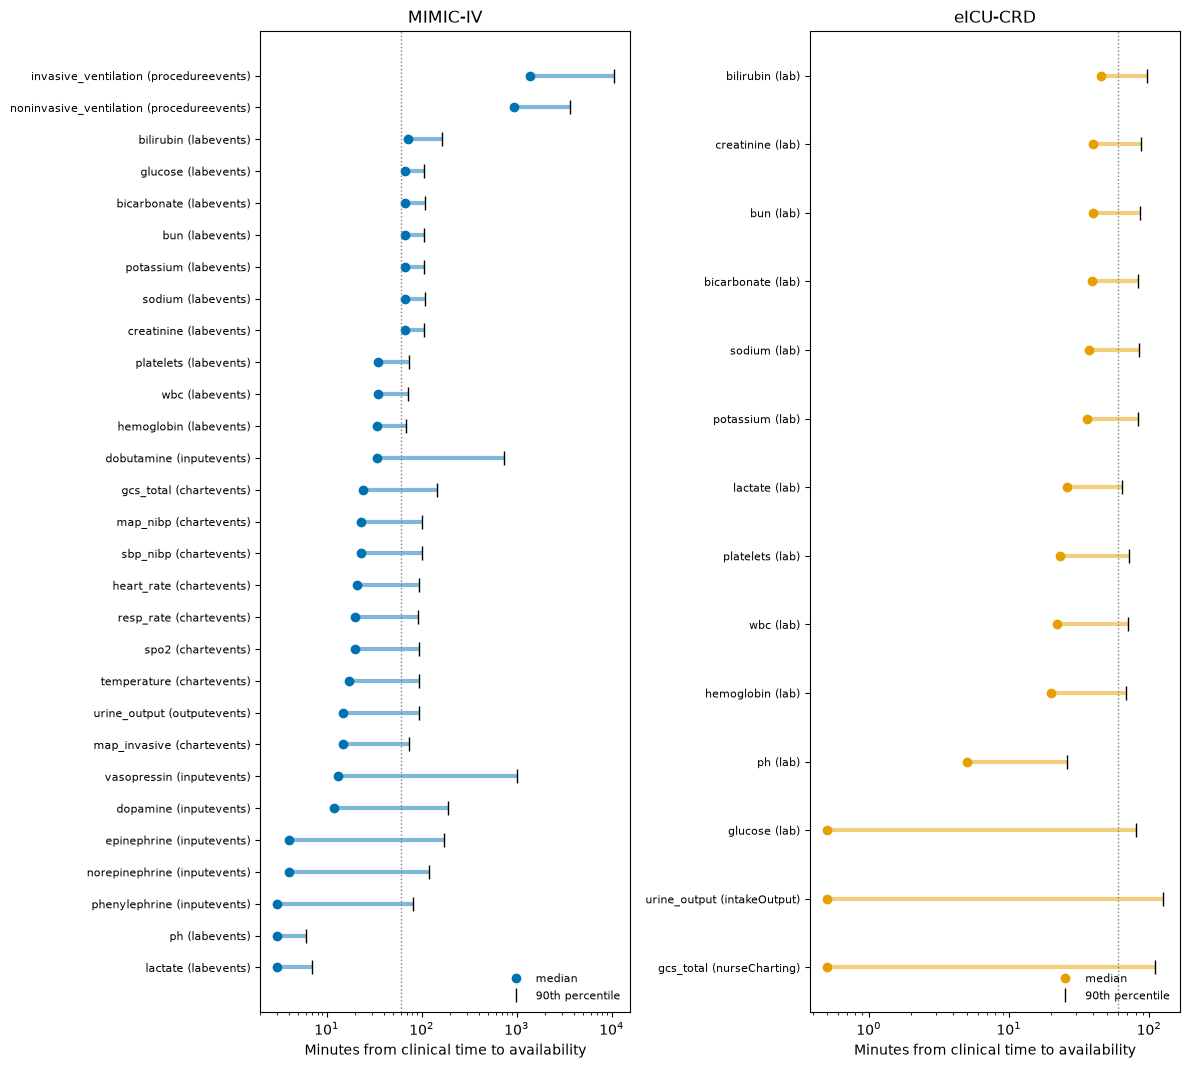

In [24]:
lags = pd.concat([t for t in LAG_TABLES if len(t)], ignore_index=True)
lags["median_lag_hours"] = lags["median_lag_min"] / 60
lags["p90_lag_hours"] = lags["p90_lag_min"] / 60
save_table(suppress(lags, ["n_events", "late_arrivals"]), "risk_availability_lag")
display(lags.sort_values(["database", "median_lag_min"], ascending=[True, False]).round(3))

plot = lags[lags["n_events"] >= MIN_CELL].copy()
plot["label"] = plot["variable"] + " (" + plot["source"].str.split(" ").str[0] + ")"
fig, axes = plt.subplots(1, 2, figsize=(12, max(3, 0.32 * plot.groupby("database").size().max() + 1.5)), sharex=False)
for ax, db in zip(axes, ("mimic-iv", "eicu")):
    d = plot[plot["database"] == db].sort_values("median_lag_min")
    if d.empty:
        ax.axis("off")
        continue
    y = np.arange(len(d))
    ax.hlines(y, d["median_lag_min"].clip(lower=0.5), d["p90_lag_min"].clip(lower=0.5), color=OKABE[db], alpha=0.5, lw=3)
    ax.plot(d["median_lag_min"].clip(lower=0.5), y, "o", color=OKABE[db], label="median")
    ax.plot(d["p90_lag_min"].clip(lower=0.5), y, "|", color="black", ms=10, label="90th percentile")
    ax.set_yticks(y)
    ax.set_yticklabels(d["label"], fontsize=8)
    ax.set_xscale("log")
    ax.set_xlabel("Minutes from clinical time to availability")
    ax.set_title(LABEL[db])
    ax.axvline(60, color="grey", ls=":", lw=1)
    ax.legend(loc="lower right", fontsize=8, frameon=False)
fig.tight_layout()
save_fig(fig, "fig_availability_lag")
plt.show()

### 6.3 Where hindsight lives: column inventory of both databases

From the timing registries in `icu-leakage-check`: tables by timing class, and the columns that record the outcome or are
only known in hindsight.

In [25]:
inv_rows, col_rows = [], []
for schema in (ilc.MIMIC_IV, ilc.EICU):
    s = schema.summary()
    for timing, n in s.groupby("timing").size().items():
        inv_rows.append({"database": schema.name, "timing_class": timing, "tables": int(n)})
    for t in schema.tables.values():
        for c in t.outcome_columns:
            col_rows.append({"database": schema.name, "table": t.name, "column": c, "role": "outcome"})
        for c in t.hindsight_columns:
            col_rows.append({"database": schema.name, "table": t.name, "column": c, "role": "hindsight"})
        if t.timing == "untimed":
            col_rows.append({"database": schema.name, "table": t.name, "column": "(whole table)", "role": "undated"})
        if t.first_day_columns:
            col_rows.append({"database": schema.name, "table": t.name, "column": f"{len(t.first_day_columns)} columns", "role": "first-day summary"})
inventory = pd.DataFrame(inv_rows)
hindsight_columns = pd.DataFrame(col_rows)
save_table(inventory, "risk_table_timing_classes")
save_table(hindsight_columns, "risk_hindsight_columns")
display(inventory.pivot(index="timing_class", columns="database", values="tables").fillna(0).astype(int))
display(hindsight_columns.groupby(["database", "role"]).size().rename("entries").to_frame())

database,eicu,mimic-iv
timing_class,,
date_only,0,3
dictionary,0,7
first_day,3,0
linked,0,2
static,2,3
timed,26,14
untimed,0,2


entries
database role                      
eicu     first-day summary        3
         hindsight               27
         outcome                  5
mimic-iv hindsight               19
         outcome                  3
         undated                  2

### 6.4 Outcome proxies: decisions documented on the way to the outcome

Care limitation (eICU-CRD care plan; MIMIC-IV code status), end-of-life discussions, and outcome-proxy billing codes of the
same admission, among deaths and survivors. *Any time* uses the whole stay, as a pipeline without timing control would;
*before prediction* uses only documentation at or before 24 hours. The univariate AUROC shows how well the flag alone
separates in-hospital mortality.

,database,proxy,deaths with flag (any time),share of deaths (any time),share of survivors (any time),share of deaths (before prediction),share of survivors (before prediction),AUROC any time,AUROC before prediction,note,"hours from first documentation to death, median"
0,MIMIC-IV,Code status other than full code (chartevents 223758),1613,0.254,0.042,0.082,0.026,0.606,0.528,,49.567
1,MIMIC-IV,"Outcome-proxy ICD code, same admission",4420,0.697,0.097,NaN,NaN,0.800,NaN,billing codes have no time; never available before predi...,NaN
2,MIMIC-IV,"Do-not-resuscitate ICD code (Z66 / V49.86), same admission",3555,0.560,0.090,NaN,NaN,0.735,NaN,,NaN
3,MIMIC-IV,"Palliative care ICD code (Z51.5 / V66.7), same admission",3140,0.495,0.027,NaN,NaN,0.734,NaN,,NaN
4,eICU-CRD,Care limitation (carePlanGeneral),7604,0.643,0.118,0.247,0.082,0.762,0.582,all stays,42.108
5,eICU-CRD,"Care limitation, stays with any care-limitation document...",7604,0.654,0.122,0.251,0.085,0.766,0.583,"125,851 stays",42.108
6,eICU-CRD,End-of-life discussion (carePlanEOL),416,0.035,0.005,0.007,0.002,0.515,0.503,,30.483


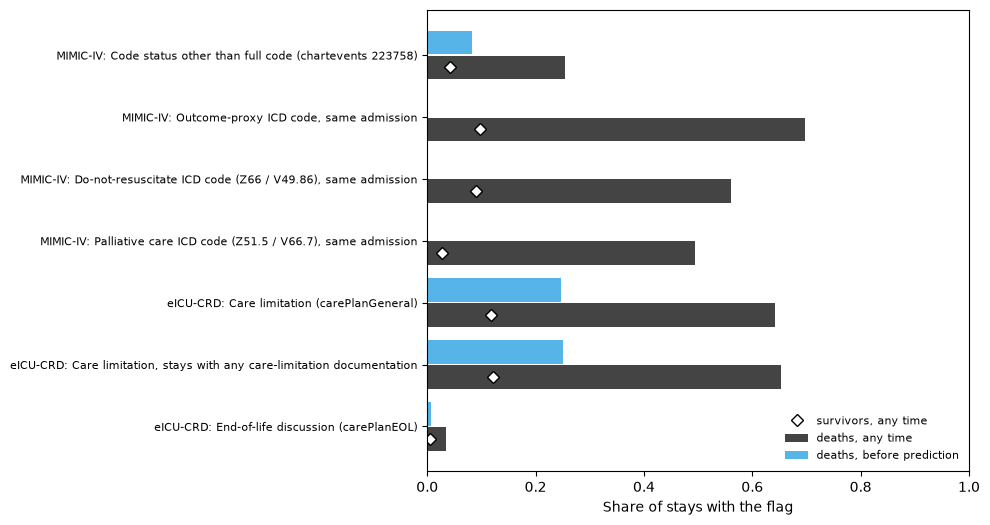

In [26]:
proxy_rows = []


def proxy_row(db, name, flag_any, flag_before, y, first_min=None, death_min=None, denom_note=""):
    y = np.asarray(y)
    row = {"database": LABEL[db], "proxy": name,
           "deaths with flag (any time)": int(flag_any[y == 1].sum()), "share of deaths (any time)": flag_any[y == 1].mean(),
           "share of survivors (any time)": flag_any[y == 0].mean(),
           "share of deaths (before prediction)": flag_before[y == 1].mean() if flag_before is not None else np.nan,
           "share of survivors (before prediction)": flag_before[y == 0].mean() if flag_before is not None else np.nan,
           "AUROC any time": ilc.auroc(y, flag_any.astype(float)),
           "AUROC before prediction": ilc.auroc(y, flag_before.astype(float)) if flag_before is not None else np.nan,
           "note": denom_note}
    if first_min is not None and death_min is not None:
        gap = (death_min - first_min)[(y == 1) & np.isfinite(first_min)] / 60
        row["hours from first documentation to death, median"] = float(np.nanmedian(gap)) if len(gap) else np.nan
    return row


cm = cohorts["mimic-iv"].merge(haz_m, on="stay_id", how="left")
y = cm["mortality"].to_numpy()
proxy_rows.append(proxy_row("mimic-iv", "Code status other than full code (chartevents 223758)",
                            cm["code_limitation_any"].to_numpy(), cm["code_limitation_before_index"].to_numpy(), y,
                            cm["code_limitation_first_min"].to_numpy(), cm["mortality_time"].to_numpy()))
proxy_rows.append(proxy_row("mimic-iv", "Outcome-proxy ICD code, same admission", cm["dx_same_adm_proxy"].to_numpy(), None, y,
                            denom_note="billing codes have no time; never available before prediction"))
proxy_rows.append(proxy_row("mimic-iv", "Do-not-resuscitate ICD code (Z66 / V49.86), same admission", cm["dx_same_adm_dnr"].to_numpy(), None, y))
proxy_rows.append(proxy_row("mimic-iv", "Palliative care ICD code (Z51.5 / V66.7), same admission", cm["dx_same_adm_palliative"].to_numpy(), None, y))

ce = cohorts["eicu"].merge(haz_e, on="stay_id", how="left")
y = ce["mortality"].to_numpy()
documented = ce["care_plan_documented"] == 1
proxy_rows.append(proxy_row("eicu", "Care limitation (carePlanGeneral)", ce["care_limitation_any"].to_numpy(),
                            ce["care_limitation_before_index"].to_numpy(), y, ce["care_limitation_first_min"].to_numpy(),
                            ce["mortality_time"].to_numpy(), denom_note="all stays"))
proxy_rows.append(proxy_row("eicu", "Care limitation, stays with any care-limitation documentation",
                            ce.loc[documented, "care_limitation_any"].to_numpy(), ce.loc[documented, "care_limitation_before_index"].to_numpy(),
                            ce.loc[documented, "mortality"].to_numpy(), ce.loc[documented, "care_limitation_first_min"].to_numpy(),
                            ce.loc[documented, "mortality_time"].to_numpy(), denom_note=f"{int(documented.sum()):,} stays"))
proxy_rows.append(proxy_row("eicu", "End-of-life discussion (carePlanEOL)", ce["eol_any"].to_numpy(), ce["eol_before_index"].to_numpy(), y,
                            ce["eol_first_min"].to_numpy(), ce["mortality_time"].to_numpy()))
proxies = pd.DataFrame(proxy_rows)
save_table(suppress(proxies, ["deaths with flag (any time)"]), "risk_outcome_proxies")
display(proxies.round(3))

fig, ax = plt.subplots(figsize=(10, 0.55 * len(proxies) + 1.5))
yy = np.arange(len(proxies))
ax.barh(yy + 0.2, proxies["share of deaths (any time)"], height=0.38, color="#444444", label="deaths, any time")
ax.barh(yy - 0.2, proxies["share of deaths (before prediction)"].fillna(0), height=0.38, color="#56B4E9", label="deaths, before prediction")
ax.plot(proxies["share of survivors (any time)"], yy + 0.2, "D", color="white", mec="black", ms=6, label="survivors, any time")
ax.set_yticks(yy)
ax.set_yticklabels(proxies["database"] + ": " + proxies["proxy"], fontsize=8)
ax.set_xlabel("Share of stays with the flag")
ax.set_xlim(0, 1)
ax.legend(fontsize=8, frameon=False, loc="lower right")
ax.invert_yaxis()
fig.tight_layout()
save_fig(fig, "fig_outcome_proxies")
plt.show()

### 6.5 When outcomes happen relative to the prediction time

Short gaps between the prediction time and the outcome make a model detect rather than predict, and they shape how much a
look-ahead leak can gain.

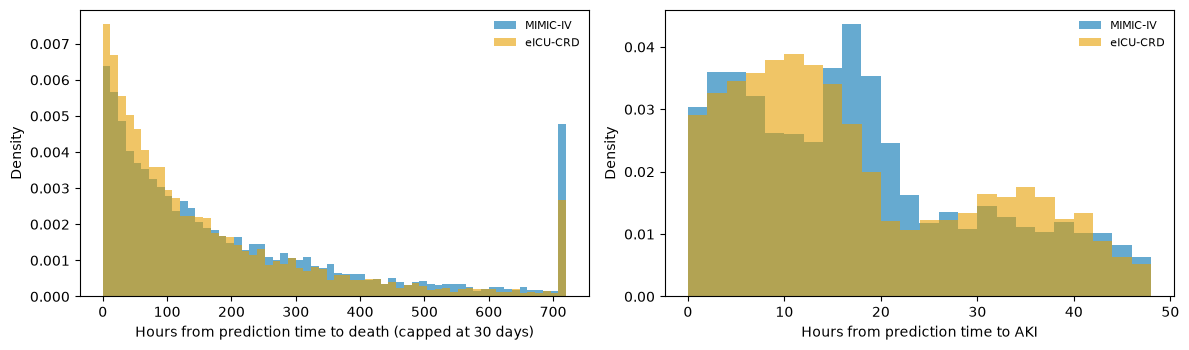

,database,task,events,median hours after prediction,within 6 h,within 24 h,within 48 h
0,MIMIC-IV,in-hospital mortality,6344,129.370,0.041,0.144,0.251
1,MIMIC-IV,AKI 24 to 72 h,6096,16.081,0.205,0.736,1.000
2,eICU-CRD,in-hospital mortality,11832,99.917,0.048,0.171,0.298
3,eICU-CRD,AKI 24 to 72 h,9901,14.233,0.192,0.700,1.000


In [27]:
timing_rows = []
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
for db, c in cohorts.items():
    for task, tcol, ycol in (("in-hospital mortality", "mortality_time", "mortality"), ("AKI 24 to 72 h", "aki_time", "aki")):
        h = ((c.loc[c[ycol] == 1, tcol] - INDEX_MIN) / 60).dropna()
        if h.empty:
            continue
        timing_rows.append({"database": LABEL[db], "task": task, "events": len(h), "median hours after prediction": h.median(),
                            "within 6 h": (h <= 6).mean(), "within 24 h": (h <= 24).mean(), "within 48 h": (h <= 48).mean()})
    h = ((c.loc[c["mortality"] == 1, "mortality_time"] - INDEX_MIN) / 60).dropna()
    axes[0].hist(h.clip(upper=30 * 24), bins=60, alpha=0.6, color=OKABE[db], label=LABEL[db], density=True)
    a = ((c.loc[c["aki"] == 1, "aki_time"] - INDEX_MIN) / 60).dropna()
    if len(a):
        axes[1].hist(a, bins=24, alpha=0.6, color=OKABE[db], label=LABEL[db], density=True)
axes[0].set_xlabel("Hours from prediction time to death (capped at 30 days)")
axes[1].set_xlabel("Hours from prediction time to AKI")
for ax in axes:
    ax.set_ylabel("Density")
    ax.legend(frameon=False, fontsize=8)
fig.tight_layout()
save_fig(fig, "fig_outcome_timing")
plt.show()
outcome_timing = pd.DataFrame(timing_rows)
save_table(suppress(outcome_timing, ["events"]), "risk_outcome_timing")
display(outcome_timing.round(3))

### 6.6 Availability of each variable at the prediction time

In [28]:
missing = pd.concat(MISSING_TABLES, ignore_index=True)
save_table(suppress(missing, ["stays_with_value"]), "risk_availability_at_prediction")
display(missing.round(3))

,database,variable,stays_with_value,share_all,share_deaths,share_survivors,missingness_auroc_mortality
0,mimic-iv,heart_rate,57460,1.000,1.000,1.000,0.500
1,mimic-iv,spo2,57448,1.000,0.999,1.000,0.500
2,mimic-iv,gcs_total,57404,0.999,0.998,0.999,0.500
3,mimic-iv,resp_rate,57396,0.999,1.000,0.999,0.500
4,mimic-iv,sodium,56476,0.983,0.980,0.983,0.502
5,mimic-iv,creatinine,56459,0.983,0.979,0.983,0.502
6,mimic-iv,bun,56449,0.982,0.979,0.983,0.502
7,mimic-iv,bicarbonate,56447,0.982,0.979,0.983,0.502
8,mimic-iv,potassium,56438,0.982,0.979,0.983,0.502
9,mimic-iv,platelets,56210,0.978,0.974,0.979,0.503


## 7. Leakage-safe baseline features and audit certification

Features use only values **available** at or before 24 hours and recorded after ICU admission (look-back window of 24 hours).
Interval events still running at the prediction time are prorated. Point measurements are summarised as last, minimum,
maximum and mean; urine output, vasoactive amounts and ventilation as sums and counts. The event rows each feature was built
from (provenance) are kept so the audit can verify every value.

The audit is run on the baseline with the patient-grouped split. A clean result here is the precondition for every
comparison in Part 2.

In [29]:
POINT_AGGS = ("last", "min", "max", "mean")
CUMULATIVE_AGGS = ("sum", "count")
CUMULATIVE = {"urine_output", "norepinephrine", "epinephrine", "vasopressin", "phenylephrine", "dopamine", "dobutamine",
              "invasive_ventilation", "noninvasive_ventilation", "mech_vent_documented"}
audit_rows = []
for db in ("mimic-iv", "eicu"):
    t0 = time.time()
    c = cohorts[db]
    ev = pd.read_parquet(DATA_DIR / f"events_{db}.parquet")
    ev = ev[(ev["event_time"] > 0) & (ev["event_time"] <= INDEX_MIN + 1e-6) | ((ev["end_time"].notna()) & (ev["event_time"] <= INDEX_MIN))]
    ev = ev.assign(variable=ev["variable"].astype(str), source=ev["source"].astype(str))
    ev = ev.astype({"value": "float64", "event_time": "float64", "available_time": "float64", "end_time": "float64"})
    idx = pd.DataFrame({"entity_id": c["stay_id"].values, "index_time": float(INDEX_MIN)})
    feats, provs = [], []
    for kind, aggs in (("point", POINT_AGGS), ("cumulative", CUMULATIVE_AGGS)):
        sub = ev[ev["variable"].isin(CUMULATIVE)] if kind == "cumulative" else ev[~ev["variable"].isin(CUMULATIVE)]
        if sub.empty:
            continue
        f, p = ilc.build_window_features(sub, idx, window=INDEX_MIN, aggregations=aggs, time_basis="available",
                                         interval_policy="prorate", return_provenance=True)
        feats.append(f)
        provs.append(p[["entity_id", "variable", "event_time", "available_time", "end_time", "index_time", "feature_prefix"]])
    features = pd.concat(feats, axis=1)
    provenance = pd.concat(provs, ignore_index=True)
    for col in ("event_time", "available_time", "end_time", "index_time"):
        provenance[col] = provenance[col].astype("float32")
    del ev, provs
    features = features.loc[:, features.notna().mean() >= 0.01]  # drop features present in under 1% of stays
    save_parquet(features.reset_index(), f"features_clean_24h_{db}")
    save_parquet(provenance, f"provenance_clean_24h_{db}")

    data = c.merge(features, left_on="stay_id", right_index=True, how="left")
    feature_cols = ["age", "female"] + list(features.columns)
    result = ilc.LeakageAudit(
        data, label="mortality", split="split_patient", dataset=db,
        patient_id="patient_id", encounter_id="encounter_id", stay_id="stay_id",
        site_id="site_id" if db == "eicu" else None,
        index_time="index_time", outcome_time="mortality_time", eligibility_time="eligibility_time",
        calendar_time="calendar_period", feature_columns=feature_cols, events=provenance, event_entity="stay_id",
        split_strategy="patient",
    ).run()
    result.to_html(PRIVATE_DIR / f"audit_clean_baseline_{db}.html")
    result.to_json(PRIVATE_DIR / f"audit_clean_baseline_{db}.json")
    frame = result.to_frame().drop(columns=["affected"])
    frame.insert(0, "database", db)
    audit_rows.append(frame)
    print(f"\n===== {LABEL[db]}: {len(feature_cols)} features, {len(provenance):,} provenance rows ({time.time() - t0:.0f} s)")
    print(result.summary())
    del provenance, data
audit_table = pd.concat(audit_rows, ignore_index=True)
save_table(audit_table, "audit_clean_baseline")


===== MIMIC-IV: 100 features, 9,037,662 provenance rows (53 s)
icu-leakage-check 0.1.0  |  dataset: mimic-iv  |  rows: 57460  features: 100
Verdict: No leakage detected by the checks that ran
Checks: 0 fail, 0 warn, 16 pass, 5 skipped

[PASS]          duplicate_records: No row of 'valid' duplicates a training row.
[PASS]          duplicate_records: No row of 'test' duplicates a training row.
[PASS]          eligibility_timing: Eligibility was known at or before every prediction time.
[PASS]          entity_overlap: No identifier is shared between splits.
[PASS]          event_timing: No events recorded after the prediction time.
[PASS]          event_timing: No events charted before the prediction time but only available after it.
[PASS]          event_timing: No interval events still running at the prediction time.
[PASS]          event_timing: No events without any time stamp.
[PASS]          hindsight_features: No hindsight, outcome, undated or early first-day variables recognised 

WindowsPath('C:/icu_leakage_work/part1/results/tables/audit_clean_baseline.csv')

## 8. Reproducibility manifest

Every output file is hashed with SHA-256. The hashes of the data and results files are sorted and hashed again, together with
the configuration and software versions, into a single chain digest. Rerunning the notebook on the same data with the same
software reproduces the same digest; any change to an output, the configuration or a software version changes it. Audit
reports carry a creation timestamp, so they are hashed individually but left out of the chain.

In [30]:
def sha256_file(path, chunk=1 << 20):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for block in iter(lambda: fh.read(chunk), b""):
            h.update(block)
    return h.hexdigest()


hazard_sources_path = DATA_DIR / "hindsight_sources.json"
hazard_sources_path.write_text(json.dumps(HAZARD_SOURCES, indent=2))
files = []
for folder in (DATA_DIR, RESULTS_DIR, PRIVATE_DIR):
    for p in sorted(folder.rglob("*")):
        if p.is_file():
            files.append({"file": str(p.relative_to(PART_DIR)).replace("\\", "/"), "bytes": p.stat().st_size, "sha256": sha256_file(p)})
chain = hashlib.sha256()
for f in sorted(files, key=lambda r: r["file"]):
    if f["file"].startswith("private_reports/"):
        continue
    chain.update(f"{f['file']}:{f['sha256']}\n".encode())
chain.update(json.dumps(CONFIG, sort_keys=True).encode())
chain.update(json.dumps({k: v for k, v in ENV.items() if k not in ("run_started_utc", "platform", "processor")}, sort_keys=True).encode())
manifest = {"part": 1, "environment": ENV, "configuration": CONFIG, "files": files, "chain_sha256": chain.hexdigest(),
            "runtime_minutes": round((time.time() - RUN_START) / 60, 1)}
(PART_DIR / "manifest_part1.json").write_text(json.dumps(manifest, indent=2))
(RESULTS_DIR / "manifest_part1.json").write_text(json.dumps(manifest, indent=2))
print(f"{len(files)} files hashed; chain digest {manifest['chain_sha256']}; runtime {manifest['runtime_minutes']} min")

35 files hashed; chain digest a84f339e2d0379e400b33d1c27efee99ba73e26c243596bd2052467c88d11eeb; runtime 8.8 min


## 9. Key numbers

In [31]:
key = {}
for db, c in cohorts.items():
    o = overlap.set_index("database").loc[LABEL[db]]
    late = lags[lags["database"] == db]
    key[LABEL[db]] = {
        "ICU stays": len(c), "patients": int(c["patient_id"].nunique()),
        "in-hospital mortality": round(float(c["mortality"].mean()), 4),
        "prolonged ICU stay": round(float(c["long_stay"].mean()), 4),
        "AKI (eligible stays)": round(float(np.nanmean(c["aki"])), 4),
        "share of stays from patients with repeat stays": round(float(o["share of stays from such patients"]), 4),
        "random row split, test stays linked to a training patient": round(float(o["random row split: test stays linked to a training patient, mean"]), 4),
        "values charted in first 24 h but available after it": int(late["late_arrivals"].sum()) if len(late) else 0,
        "share of first-24 h values arriving late": round(float(late["late_arrivals"].sum() / late["n_events"].sum()), 4) if len(late) else None,
        "baseline audit failures": int(((audit_table["database"] == db) & (audit_table["status"] == "fail")).sum()),
        "baseline audit warnings": int(((audit_table["database"] == db) & (audit_table["status"] == "warn")).sum()),
    }
(RESULTS_DIR / "key_numbers_part1.json").write_text(json.dumps(key, indent=2))
display(pd.DataFrame(key).astype(object))
print(f"Total runtime: {(time.time() - RUN_START) / 60:.1f} minutes")
con.close()

,MIMIC-IV,eICU-CRD
ICU stays,57460.0,129258.0
patients,42067.0,102154.0
in-hospital mortality,0.1104,0.0915
prolonged ICU stay,0.2872,0.2559
AKI (eligible stays),0.1397,0.0941
share of stays from patients with repeat stays,0.4258,0.3548
"random row split, test stays linked to a training patient",0.3538,0.2833
values charted in first 24 h but available after it,297378.0,84818.0
share of first-24 h values arriving late,0.0273,0.0212
baseline audit failures,0.0,0.0


Total runtime: 8.8 minutes


## What Part 2 builds on

* `data/cohort_<db>.parquet`: one row per stay with identifiers, three task labels and their outcome times, eligibility time,
  calendar period and the three split assignments.
* `data/events_<db>.parquet`: two-clock event log (clinical and availability time, interval end time) up to 48 hours after admission.
* `data/hindsight_<db>.parquet` and `data/hindsight_sources.json`: hindsight and proxy fields with their source columns.
* `data/features_clean_24h_<db>.parquet` and `data/provenance_clean_24h_<db>.parquet`: the certified leakage-safe baseline.

Part 2 switches on one leakage mechanism at a time against this baseline (patient overlap, look-ahead features, availability
lag, interval totals, hindsight fields, same-admission billing codes, early use of first-day summaries, outcome proxies,
preprocessing fitted on all rows and oversampling before the split) and measures the inflation of discrimination and
calibration on identical test patients with patient-level bootstrap intervals.

**Definitions used**

* MIMIC-IV documentation for `chartevents` and `labevents` (meaning of `charttime` and `storetime`): https://mimic.mit.edu/docs/iv/
* MIT-LCP `mimic-code` concepts (vital signs, GCS, urine output, vasoactive agents, KDIGO creatinine, code status): https://github.com/MIT-LCP/mimic-code
* MIT-LCP `eicu-code` concepts (pivoted laboratory, vital, GCS, urine output and infusion tables): https://github.com/MIT-LCP/eicu-code
* KDIGO Clinical Practice Guideline for Acute Kidney Injury (2012), creatinine criteria.